# Belajar kode ML Essenza — dari dataset sampai prediksi

Notebook ini adalah panduan membaca **implementasi penelitian yang sebenarnya**:
lima sumber Pyrfume, Morgan 2048, delapan deskriptor RDKit, XGBoost/LightGBM,
dan Optuna. Nama versi di alamat file dipertahankan untuk menelusuri arsip,
bukan sebagai nama metode penelitian.

**Cara belajarnya:** baca penjelasan → baca kode asli → jalankan contoh ringan →
cocokkan output → jawab pertanyaan latihan. Kode lengkap di `KODE_ML` ditampilkan
di bagian masing-masing. Implementasi inti juga disertakan pada lampiran.

**Run All hanya membaca artefak, menghitung fitur contoh, memeriksa metrik,
dan menjalankan prediksi.** Tidak ada pemanggilan training, tuning, unduhan dataset,
atau penulisan ulang dataset/model. Kode training asli ditampilkan sebagai Markdown
agar bisa dipelajari tanpa memulai eksperimen panjang.

Notebook dibuat dari file proyek pada **23 Oktober 2026**. Output contoh disimpan
setelah eksekusi, sehingga kamu bisa langsung membaca tanpa menyalakan kernel.

## Daftar isi

1. [Tujuan dan peta kode](#tujuan)
2. [Setup dan alamat file](#setup)
3. [Data mentah, cleaning, dan EDA](#data)
4. [SMILES menjadi fitur](#fitur)
5. [Train/test, fold, dan seed](#split)
6. [Classifier, ketimpangan kelas, dan fitting](#model)
7. [Optuna: mencari resep parameter](#optuna)
8. [Validasi berulang, OOF, dan pemilihan kandidat](#oof)
9. [Fitting final dan evaluasi test](#evaluasi)
10. [Prediksi satu molekul](#prediksi)
11. [Lokasi seluruh hasil dan pemeriksaan akhir](#hasil)
12. [Latihan sidang dan jawaban](#latihan)
13. [Lampiran kode implementasi inti](#lampiran)

Jika baru mulai, pelajari bagian 1–5 dahulu. Lanjutkan 6–10 setelah kamu bisa
menjelaskan perbedaan **fitur X**, **target y**, dan **skor prediksi**.

<a id="tujuan"></a>
## 1. Tujuan dan peta kode

**Pertanyaan penelitian:** pada dataset yang digunakan, bagaimana performa
XGBoost dan LightGBM, serta apa perubahan hasil ketika fitur ditambah dan
parameter dicari memakai Optuna?

```text
Lima sumber → cocokkan identitas → validasi struktur/label → gabung molekul
→ target 0/1 → grup dan split → Morgan/deskriptor → baseline/tuning
→ validasi berulang → bekukan kandidat → fitting final → test → prediksi
```

| File di KODE_ML | Input | Output/peran |
|---|---|---|
| `_lokasi.py` | Letak repositori | Alamat data, fitur, protokol, dan run |
| `00_preprocessing_dan_eda.ipynb` | Hasil preprocessing | Tabel dan grafik dataset |
| `01_fitur.py` | Satu SMILES | Morgan 2048 dan 8 deskriptor |
| `02_split.py` | Split tersimpan | Pemeriksaan train/test dan contoh fold |
| `03_optuna.py` | Protokol dan trials.csv | Ringkasan tuning yang sudah selesai |
| `04_training_evaluasi.py` | Tabel hasil dan prediksi tersimpan | Perbandingan serta pemeriksaan AP/F1 |
| `05_prediksi.py` | SMILES dan model tersimpan | Skor serta keputusan 109 label |
| `README.md` | Dokumentasi | Petunjuk penggunaan dan lokasi hasil |
| `PANDUAN_SIDANG_KODE.md` | Audit implementasi | Konsep, catatan kerumitan, latihan sidang |

Notebook `00` tetap tersedia khusus preprocessing. Notebook ini menggabungkan
penjelasan alur lengkap dan membawa pembaca sampai ke implementasi training asli.

<a id="setup"></a>
## 2. Setup — mulai dari sel ini ketika ingin menjalankan

Buka notebook dari folder `KODE_ML` dan pilih Python `.venv` proyek di VS Code/Jupyter.
Dependensi penelitian harus sesuai environment tersimpan. Untuk menjalankan notebook,
kernel juga memerlukan `ipykernel`; jika belum ada, VS Code dapat memasangnya saat
pemilihan kernel. Membaca output tersimpan tidak memerlukan kernel.

Sel berikut mencari root repositori dari lokasi kerja, lalu mengimpor library.
`sys.dont_write_bytecode` mencegah pembuatan cache Python saat contoh dijalankan.
Jika membuka dari luar repositori, set environment `ML_REPO_ROOT` ke root proyek.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys

sys.dont_write_bytecode = True
repo_hint = os.environ.get("ML_REPO_ROOT")
calon_root = [Path(repo_hint)] if repo_hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in calon_root if (p / "alignment/protocol_v7.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka dari folder repo/KODE_ML atau set ML_REPO_ROOT.")
for folder in (ROOT, ROOT / "KODE_ML"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from _lokasi import DATA, FITUR, PROTOKOL, baca_json, hasil_penelitian

RUN = hasil_penelitian()
protokol = baca_json(PROTOKOL)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 10, "axes.grid": False})
display(pd.DataFrame({"Isi": ["Root proyek", "Dataset", "Fitur aktual", "Hasil penelitian"],
                      "Alamat": [str(ROOT), str(DATA), str(FITUR), str(RUN)]}))
print("Python:", sys.executable)

,Isi,Alamat
0,Root proyek,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier
1,Dataset,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
2,Fitur aktual,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
3,Hasil penelitian,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....


Python: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.venv\Scripts\python.exe


### 2.1 `_lokasi.py` — kenapa alamat dipisahkan?

Supaya setiap skrip memakai dataset dan hasil yang sama. `ROOT` diperoleh dari
letak file, sedangkan `hasil_penelitian()` mencari run yang mempunyai `complete.json`.
Urutannya root `runs/` dahulu, lalu folder kampus yang ditetapkan. Ia tidak memilih
eksperimen terbaru secara otomatis.

`baca_json()` mengubah isi berkas JSON menjadi dictionary/list Python.
Tanda `/` pada objek `Path` menyambung bagian alamat folder.

**Kode asli:** [KODE_ML/_lokasi.py](_lokasi.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Lokasi artefak penelitian. Tidak mengubah data atau hasil eksperimen."""

import json
from pathlib import Path


ROOT = Path(__file__).resolve().parents[1]
DATA = ROOT / "data" / "builds" / "perfume-five-grouped-v2"
FITUR = ROOT / "data" / "builds" / "perfume-m2048-d8-v7"
PROTOKOL = ROOT / "alignment" / "protocol_v7.json"
RUN_ID = "perfume-five-grouped-v7-m2048-d8"
RUN_KAMPUS = (
    ROOT
    / ".local-tools"
    / "campus-transfer-full-20260909"
    / "perfume-campus-grouped-v7-m2048-d8"
    / "perfume-campus-grouped-v7-m2048-d8"
    / "runs"
    / RUN_ID
)


def baca_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))


def hasil_penelitian() -> Path:
    """Pilih hasil yang ada; laporan dan data tidak diubah."""
    for path in (ROOT / "runs" / RUN_ID, RUN_KAMPUS):
        if (path / "complete.json").exists():
            return path
    raise FileNotFoundError(
        "Hasil eksperimen utama tidak ditemukan. Periksa folder runs/ atau hasil kampus; "
        "jangan mengulang training hanya untuk membaca kodenya."
    )
```

### 2.2 Cara membedakan kode baca dan kode jalan

- Blok **Kode asli** berwarna sintaks di bawah penjelasan adalah isi berkas untuk dibaca.
- Sel dengan tombol Run menjalankan contoh ringan di notebook ini.
- `def` mendefinisikan fungsi; isi fungsi berjalan ketika dipanggil.
- Bagian `if __name__ == "__main__":` adalah pintu masuk ketika skrip dijalankan dari terminal.
  Bagian CLI itu ditampilkan sebagai Markdown, sehingga argumen Jupyter tidak dibaca sebagai argumen skrip.

**Latihan:** tunjukkan pada kode di atas variabel yang menentukan folder fitur aktual.
Jawabannya `FITUR`, bukan `DATA`.

<a id="data"></a>
## 3. Dataset, preprocessing, dan EDA

Lima sumber yang dipilih: **GoodScents, IFRA 2019, Leffingwell, Arctander 1960,
dan Sigma-Aldrich 2014**. Sumber tersebut relevan dengan konteks bahan/aroma parfum,
tetapi bukan bukti bahwa setiap rekamannya merupakan bahan parfum eksklusif.

Tabel sumber memisahkan informasi struktur molekul, stimulus/identitas, dan anotasi aroma.
Kode harus mencocokkan identitas sebelum menggabungkan label dengan SMILES.
Jangan menggabungkan tabel berdasarkan nomor baris semata.

In [2]:
konfigurasi_data = baca_json(DATA / "config.json")
display(pd.DataFrame.from_dict(konfigurasi_data["sources"], orient="index"))
snapshot = ROOT / "data/snapshots/perfume-five-v1" / konfigurasi_data["revision"]
print("Snapshot sumber:", snapshot)
print("Commit Pyrfume:", konfigurasi_data["revision"])

,molecules,stimuli,behavior
goodscents,goodscents/molecules.csv,goodscents/stimuli.csv,goodscents/behavior.csv
ifra,ifra_2019/molecules.csv,ifra_2019/stimuli.csv,ifra_2019/behavior.csv
leffingwell,leffingwell/molecules.csv,leffingwell/stimuli.csv,leffingwell/behavior.csv
arctander,arctander_1960/molecules.csv,arctander_1960/stimuli.csv,arctander_1960/behavior_1_sparse.csv
sigma,sigma_2014/molecules.csv,sigma_2014/stimuli.csv,sigma_2014/behavior.csv


Snapshot sumber: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\snapshots\perfume-five-v1\8054ea98ed675005ec10e67359902f500e4911b0
Commit Pyrfume: 8054ea98ed675005ec10e67359902f500e4911b0


### 3.1 Kode preprocessing asli — apa urutannya?

Implementasinya ada di `alignment/perfume_data.py`:

| Fungsi | Tugas | Hasil |
|---|---|---|
| `load_config` | Memastikan lima sumber dan aturan yang diizinkan | Konfigurasi |
| `load_sources` | Membaca snapshot dan memeriksa checksum | Tabel sumber |
| `taxonomy_from_ifra` | Membentuk kamus istilah dari IFRA | Daftar istilah |
| `tokens_for` | Membaca label sesuai format tiap sumber | Token aroma |
| `map_labels` | Mencocokkan istilah exact/alias eksplisit | Label baku |
| `merge_sources` | Memvalidasi struktur, menggabungkan molekul sama dan labelnya | Records, audit, provenance |
| `encode_and_split` | Target 0/1, grup, train/test, seleksi label, fold per label | Target dan split |
| `prepare` | Menjalankan tahapan dan menyimpan build baru | Berkas dataset |

`load_sources` dan `prepare` tidak dipanggil dalam notebook ini karena dapat mengunduh
atau menulis build. Kode lengkapnya tersedia pada lampiran.

Pencocokan identitas memakai helper `src/build_dataset.py`: hubungan Stimulus → CID → SMILES,
serta CAS untuk Sigma. Nilai identitas yang ambigu tidak ditebak.

**Kode asli:** [alignment/perfume_data.py](../alignment/perfume_data.py), baris 116-128, fungsi `map_labels`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def map_labels(tokens, taxonomy, source, unmapped, mappings):
    accepted = set()
    for token in tokens:
        if not isinstance(token, str) or not token.strip():
            continue
        term = normalize(token)
        mapped = term if term in taxonomy else ALIASES.get(term)
        if mapped in taxonomy:
            accepted.add(mapped)
            mappings[(source, term, mapped, "exact" if term == mapped else "alias")] += 1
        else:
            unmapped[(source, term)] += 1
    return accepted
```

**Cara membaca `map_labels`:** lewati token kosong, normalisasi teks, coba padanan langsung
atau alias yang ditetapkan, lalu simpan label yang ada dalam kamus. Istilah yang tidak cocok
dicatat di `unmapped`, sehingga kehilangan informasi bisa dilacak.

Untuk molekul dengan SMILES kanonik sama, `merged[canonical].update(labels)` pada
`merge_sources` menggabungkan label positif yang tercatat. Ini merupakan kebijakan anotasi
penelitian; perbedaan kelengkapan sumber masih menjadi keterbatasan data.

### 3.2 Lihat jumlah baris yang diterima dan ditolak

Sel berikut membaca audit yang sudah tersimpan. Rekaman sumber belum sama dengan jumlah
molekul unik: satu molekul bisa tercatat di lebih dari satu sumber.

In [3]:
audit = baca_json(DATA / "audit.json")
tabel_sumber = pd.DataFrame.from_dict(audit["sources"], orient="index")
tabel_sumber["ditolak"] = tabel_sumber["rows"] - tabel_sumber["accepted"]
display(tabel_sumber[["rows", "accepted", "ditolak", "missing_identity", "multifragment",
                       "empty_labels", "unmapped_labels"]])
print("Total rekaman sumber:", int(tabel_sumber["rows"].sum()))
print("Diterima sebelum merge:", int(tabel_sumber["accepted"].sum()))
print("Ditolak:", int(tabel_sumber["ditolak"].sum()))

,rows,accepted,ditolak,missing_identity,multifragment,empty_labels,unmapped_labels
goodscents,4626,4104,522,0,183,4,335
ifra,1146,1118,28,0,28,0,0
leffingwell,3522,3408,114,0,0,0,114
arctander,3102,2440,662,278,102,209,73
sigma,941,707,234,204,0,0,30


Total rekaman sumber: 13337
Diterima sebelum merge: 11777
Ditolak: 1560


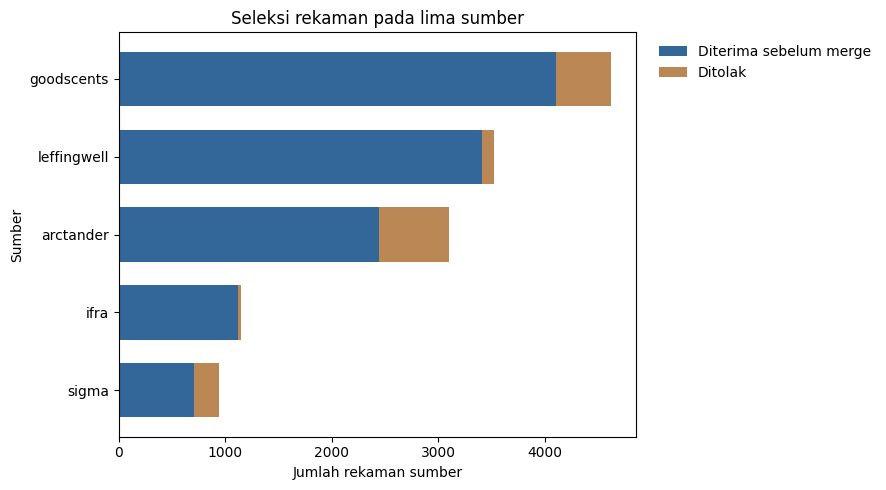

In [4]:
ax = tabel_sumber.sort_values("rows")[["accepted", "ditolak"]].plot.barh(
    stacked=True, color=["#336699", "#bb8855"], width=0.7)
ax.set(title="Seleksi rekaman pada lima sumber", xlabel="Jumlah rekaman sumber", ylabel="Sumber")
ax.set_xlim(left=0)
ax.legend(["Diterima sebelum merge", "Ditolak"], frameon=False,
          loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Bacaan grafik:** panjang batang menunjukkan rekaman awal tiap sumber; bagian biru
menunjukkan yang lolos sebelum molekul identik digabung. Angka ini bukan jumlah molekul
unik per sumber yang bisa langsung dijumlahkan menjadi ukuran dataset akhir.

In [5]:
records = pd.read_csv(DATA / "records.csv")
records["labels"] = records["labels"].map(json.loads)
records["sources"] = records["sources"].map(json.loads)
display(records.head(3))
print("Molekul akhir:", len(records))
print("SMILES kosong:", int(records["smiles"].isna().sum()))
print("Duplikat SMILES:", int(records["smiles"].duplicated().sum()))
print("Molekul tercatat di lebih dari satu sumber:", int(records["sources"].map(len).gt(1).sum()))
print("Rekaman diterima yang tergabung:", int(tabel_sumber["accepted"].sum() - len(records)))

,source_row,smiles,labels,sources
0,0,BrC=Cc1ccccc1,"[floral, green, hyacinth, leafy]","[arctander, goodscents]"
1,1,C#CC(C)(O)CCC=C(C)C,"[dry, musk like, sweet, waxy, woody]",[goodscents]
2,2,C#CC(C)CO,"[ethereal, green]",[arctander]


Molekul akhir: 6686
SMILES kosong: 0
Duplikat SMILES: 0
Molekul tercatat di lebih dari satu sumber: 2808
Rekaman diterima yang tergabung: 5091


### 3.3 Hapus data kosong — apa yang sebenarnya dilakukan?

Implementasi tidak mengisi SMILES yang tidak diketahui dengan tebakan. Baris ditolak jika
identitas tidak cocok, struktur tidak valid/lebih dari satu komponen, label kosong,
nilai anotasi tidak valid, atau tidak ada istilah yang cocok dengan kamus.

`records.csv` adalah hasil setelah seleksi dan merge. Notebook ini hanya membacanya.

In [6]:
alasan = ["missing_identity", "invalid_smiles", "multifragment", "empty_labels",
          "unmapped_labels", "invalid_behavior"]
display(tabel_sumber[alasan].sum().sort_values(ascending=False).rename("Jumlah ditolak").to_frame())
display(pd.read_csv(DATA / "label_mappings.csv").head(8))

,Jumlah ditolak
unmapped_labels,552
missing_identity,482
multifragment,313
empty_labels,213
invalid_smiles,0
invalid_behavior,0


,source,raw_descriptor,label,method,count
0,arctander,aldehydic,aldehydic,exact,22
1,arctander,almond,almond,exact,27
2,arctander,animal,animal like,alias,73
3,arctander,anisic,anisic,exact,38
4,arctander,apple,apple,exact,64
5,arctander,apricot,apricot,exact,33
6,arctander,aromatic,aromatic,exact,17
7,arctander,balsamic,balsamic,exact,238


### 3.4 Label encoding — bedakan X dan y

**X = fitur struktur. y = target aroma dari anotasi dataset.** Untuk setiap molekul,
ada 109 kolom target. Nilai 1 berarti label tercatat, 0 berarti tidak tercatat dalam
target gabungan. **Nol bukan bukti pengujian sensoris bahwa aroma tersebut pasti tidak ada.**

Pemilihan label memakai dukungan data train, bukan peringkat performa di test.
Kamus IFRA memuat 184 istilah; 109 memenuhi aturan seleksi.

In [7]:
manifest = baca_json(DATA / "dataset_manifest.json")
labels = manifest["labels"]
with np.load(DATA / "train.npz", allow_pickle=False) as z:
    y_train = z["truth"].copy()
    train_rows = z["row_index"].astype(int)
with np.load(DATA / "test.npz", allow_pickle=False) as z:
    y_test = z["truth"].copy()
    test_rows = z["row_index"].astype(int)
display(pd.DataFrame(y_train[:5, :8], columns=labels[:8], index=train_rows[:5]))
print("Target train:", y_train.shape, "| test:", y_test.shape, "| tipe:", y_train.dtype)
print("Jumlah istilah kamus:", len(manifest["taxonomy"]), "| target terpilih:", len(labels))
print("Baris train seluruh target nol:", int((y_train.sum(axis=1) == 0).sum()))

,acidic,aldehydic,almond,amber,animal like,anisic,apple,apricot
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0


Target train: (5353, 109) | test: (1333, 109) | tipe: uint8
Jumlah istilah kamus: 184 | target terpilih: 109
Baris train seluruh target nol: 11


Ada baris yang punya label pada records asli tetapi menjadi seluruhnya nol setelah
target dibatasi pada 109 label terpilih. Jadi pemeriksaan 'records tanpa label'
dan 'target seluruh nol' menghitung dua kondisi yang berbeda.

### 3.5 Distribusi label — mengapa accuracy saja tidak cukup?

Beberapa label jauh lebih sering muncul daripada label lain. Model yang sering menebak nol
bisa memperoleh accuracy tinggi tanpa berhasil menemukan label positif yang jarang.

,Molekul positif train
rooty,32
popcorn,34
narcissus,34
celery,34
raspberry,35
neroli,35
marine,35
acidic,36


Min/median/max positif: 32 100.0 1987


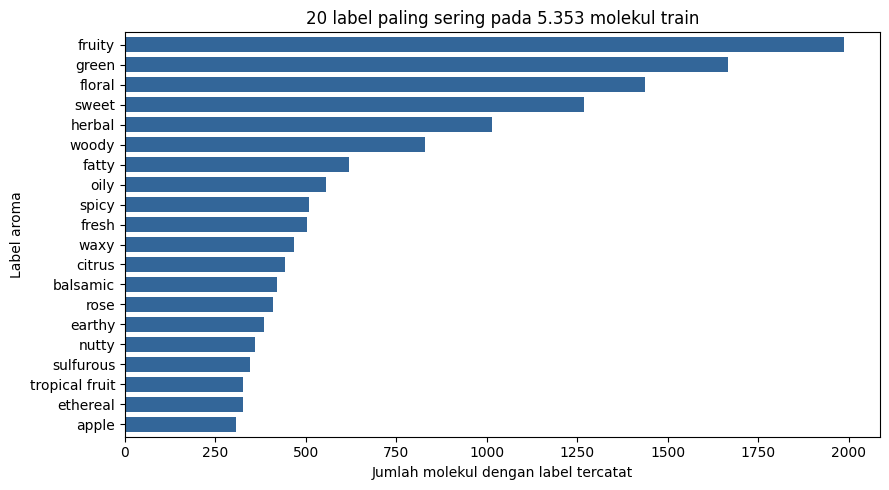

In [8]:
dukungan = pd.Series(y_train.sum(axis=0), index=labels, name="Molekul positif train").sort_values()
display(dukungan.head(8).to_frame())
print("Min/median/max positif:", int(dukungan.min()), float(dukungan.median()), int(dukungan.max()))
ax = dukungan.tail(20).plot.barh(color="#336699", width=0.75)
ax.set(title="20 label paling sering pada 5.353 molekul train",
       xlabel="Jumlah molekul dengan label tercatat", ylabel="Label aroma")
ax.set_xlim(left=0)
plt.tight_layout()
plt.show()

**Yang sudah terlihat:** distribusi tidak seimbang, label langka mempunyai dukungan terbatas.
Pemeriksaan ini belum membuktikan seluruh anotasi antarsumber benar atau lengkap.

**Latihan:** pilih satu baris records. Jelaskan mengapa jumlah `sources` bukan jumlah molekul,
dan mengapa nama aroma yang sama pada dua SMILES berbeda bukan duplikasi molekul.

<a id="fitur"></a>
## 4. SMILES menjadi fitur — `01_fitur.py`

Script menerima satu SMILES, menghitung Morgan dan deskriptor, lalu menampilkan dimensinya.
Input default adalah vanilin. Berikut isi lengkap script; bagian CLI hanya membaca `--smiles`.

**Kode asli:** [KODE_ML/01_fitur.py](01_fitur.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""SMILES -> Morgan 2048 + delapan deskriptor; demonstrasi satu molekul."""

import argparse
import sys

import numpy as np

from _lokasi import ROOT

sys.path.insert(0, str(ROOT))
from alignment.descriptors_v7 import DESCRIPTORS8, calculate, calculate_morgan  # noqa: E402
from alignment.experiments_v7 import features  # noqa: E402


def periksa_fitur(smiles: str) -> None:
    morgan = calculate_morgan([smiles])
    deskriptor = calculate([smiles])
    print(f"SMILES: {smiles}")
    print(f"Morgan: {morgan.shape[1]} bit biner; bit aktif: {int(morgan.sum())}")
    for nama, nilai in zip(DESCRIPTORS8, deskriptor[0]):
        print(f"  {nama:<20} {float(nilai):.4f}")
    print(f"A/C: {features('xgb_A', morgan, deskriptor).shape[1]} fitur")
    print(f"B/D: {features('xgb_D', morgan, deskriptor).shape[1]} fitur")
    assert np.isin(morgan, [0, 1]).all()


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--smiles", default="COc1cc(C=O)ccc1O", help="Satu molekul valid; default vanilin")
    periksa_fitur(parser.parse_args().smiles)
```

### 4.1 Apa yang dikerjakan RDKit?

RDKit membaca SMILES menjadi graf molekul. `calculate_morgan` membuat fingerprint 2048 bit
dengan radius 2 dan tanpa chirality. `calculate` memanggil delapan fungsi deskriptor yang
namanya sudah ditetapkan. Morgan bukan kode biner karakter SMILES.

| Deskriptor | Informasi |
|---|---|
| MolWt | Berat molekul |
| MolLogP | Perkiraan kecenderungan lemak dibanding air |
| NumHDonors | Jumlah donor ikatan hidrogen |
| NumHAcceptors | Jumlah akseptor ikatan hidrogen |
| TPSA | Luas permukaan polar berdasarkan struktur |
| NumRotatableBonds | Jumlah ikatan berotasi |
| HeavyAtomCount | Jumlah atom selain H |
| RingCount | Jumlah cincin |

**Kode asli:** [alignment/descriptors_v7.py](../alignment/descriptors_v7.py), baris 38-42, fungsi `calculate_morgan`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def calculate_morgan(smiles):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=RADIUS, fpSize=N_BITS, includeChirality=False)
    return np.asarray([generator.GetFingerprintAsNumPy(molecule(smi, i))
                       for i, smi in enumerate(smiles)], dtype=np.uint8)
```

**Kode asli:** [alignment/descriptors_v7.py](../alignment/descriptors_v7.py), baris 28-35, fungsi `calculate`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def calculate(smiles):
    values = np.empty((len(smiles), 8), dtype=np.float32)
    for i, value in enumerate(smiles):
        mol = molecule(value, i)
        values[i] = [getattr(Descriptors, name)(mol) for name in DESCRIPTORS8]
    if not np.isfinite(values).all():
        raise ValueError("Nonfinite descriptors; no silent imputation.")
    return values
```

In [9]:
from alignment.descriptors_v7 import DESCRIPTORS8, calculate, calculate_morgan
from alignment.experiments_v7 import features

SMILES_CONTOH = "COc1cc(C=O)ccc1O"
morgan_contoh = calculate_morgan([SMILES_CONTOH])
deskriptor_contoh = calculate([SMILES_CONTOH])
display(pd.DataFrame(deskriptor_contoh, columns=DESCRIPTORS8))
print("SMILES:", SMILES_CONTOH)
print("Morgan:", morgan_contoh.shape, morgan_contoh.dtype)
print("Bit aktif:", int(morgan_contoh.sum()))
print("40 posisi pertama:", morgan_contoh[0, :40].tolist())
assert np.isin(morgan_contoh, [0, 1]).all()

C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,MolWt,MolLogP,NumHDonors,NumHAcceptors,TPSA,NumRotatableBonds,HeavyAtomCount,RingCount
0,152.149002,1.2133,1.0,3.0,46.529999,2.0,11.0,1.0


SMILES: COc1cc(C=O)ccc1O
Morgan: (1, 2048) uint8
Bit aktif: 25
40 posisi pertama: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


`[SMILES_CONTOH]` berarti daftar berisi satu molekul. Karena itu shape mempunyai satu baris.
Bit aktif adalah posisi Morgan bernilai 1, bukan jumlah aroma atau jumlah atom.

### 4.2 Empat skenario dan dua algoritma

| Skenario | Fitur | Hyperparameter |
|---|---|---|
| A | Morgan 2048 | Baseline proyek |
| B | Morgan 2048 + 8 deskriptor | Baseline proyek |
| C | Morgan 2048 | Optuna |
| D | Morgan 2048 + 8 deskriptor | Optuna |

Masing-masing diterapkan pada XGBoost dan LightGBM → **8 kandidat**.
Baseline memakai `n_estimators=100`, ditambah aturan umum implementasi seperti bobot kelas.
Ini baseline internal proyek, bukan reproduksi seluruh dataset/prosedur Suh.

**Kode asli:** [alignment/experiments_v7.py](../alignment/experiments_v7.py), baris 34-38, fungsi `features`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def features(key, morgan, descriptors):
    if (morgan.ndim != 2 or morgan.shape[1] != N_BITS or descriptors.shape != (len(morgan), 8)
            or not np.isfinite(descriptors).all()):
        raise ValueError("Expected Morgan 2048 and eight ordered descriptors per molecular row.")
    return np.column_stack([morgan, descriptors[:, :descriptor_count(key)]]).astype(np.float32)
```

In [10]:
for kondisi in "ABCD":
    x_contoh = features(f"lgbm_{kondisi}", morgan_contoh, deskriptor_contoh)
    print(f"Kondisi {kondisi}: {x_contoh.shape}, tipe {x_contoh.dtype}")
print("Contoh delapan kolom terakhir D:", x_contoh[0, -8:].tolist())

Kondisi A: (1, 2048), tipe float32
Kondisi B: (1, 2056), tipe float32
Kondisi C: (1, 2048), tipe float32
Kondisi D: (1, 2056), tipe float32
Contoh delapan kolom terakhir D: [152.1490020751953, 1.2132999897003174, 1.0, 3.0, 46.529998779296875, 2.0, 11.0, 1.0]


`np.column_stack` menyambung kolom. Hasil gabungan dibuat `float32`, sehingga bit Morgan
akan tampil 0.0/1.0 tanpa mengubah nilai bit tersebut.

### 4.3 Cocokkan dengan fitur seluruh dataset

`train.npz`/`test.npz` masih membawa fitur build dasar 1024+5. Fitur aktual 2048+8 disimpan
terpisah di `FITUR/features.npz`; indeks baris menjaga hubungan dengan target.

In [11]:
with np.load(FITUR / "features.npz", allow_pickle=False) as z:
    morgan_semua = z["morgan"].copy()
    deskriptor_semua = z["descriptors"].copy()
    indeks_fitur = z["row_index"].copy()
    nama_deskriptor = z["names"].tolist()
assert nama_deskriptor == list(DESCRIPTORS8)
assert np.array_equal(indeks_fitur, np.arange(len(records)))
x_train_d = features("lgbm_D", morgan_semua[train_rows], deskriptor_semua[train_rows])
print("Morgan semua:", morgan_semua.shape)
print("Deskriptor semua:", deskriptor_semua.shape)
print("X train D:", x_train_d.shape, "| y train:", y_train.shape)

Morgan semua: (6686, 2048)
Deskriptor semua: (6686, 8)
X train D: (5353, 2056) | y train: (5353, 109)


**Latihan:** mengapa X mempunyai 2056 kolom sedangkan y mempunyai 109 kolom?
X menggambarkan struktur; y menggambarkan target aroma. Keduanya mempunyai jumlah baris molekul yang sama.

<a id="split"></a>
## 5. Train/test, fold, dan seed — `02_split.py`

Script berikut membaca split tersimpan, memeriksa overlap grup train/test, lalu memperlihatkan
lima fold untuk label pertama. Ia tidak membentuk ulang seluruh split.

**Kode asli:** [KODE_ML/02_split.py](02_split.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Lihat pembagian train/test dan satu contoh fold berkelompok tanpa training."""

import sys

import numpy as np

from _lokasi import DATA, PROTOKOL, ROOT, baca_json

sys.path.insert(0, str(ROOT))


def periksa_split() -> None:
    split = baca_json(DATA / "splits.json")
    protokol = baca_json(PROTOKOL)
    kelompok = np.asarray(split["groups"])
    train, test = np.asarray(split["train"]), np.asarray(split["test"])
    bocor = set(kelompok[train]) & set(kelompok[test])
    if bocor:
        raise AssertionError(f"Ada {len(bocor)} grup di train dan test!")

    label = split["eligible_labels"][0]
    folds = split["folds"][label]
    print(f"Molekul: {len(kelompok)}; train: {len(train)}; test: {len(test)}")
    print(f"Grup bocor train-test: {len(bocor)}")
    print(f"Contoh label: {label}; jumlah fold: {len(folds)}")
    for nomor, fold in enumerate(folds, start=1):
        a, b = np.asarray(fold["train"]), np.asarray(fold["validation"])
        if set(kelompok[a]) & set(kelompok[b]):
            raise AssertionError(f"Fold {nomor} memiliki kebocoran grup.")
        print(f"  Fold {nomor}: {len(a)} latih, {len(b)} validasi")
    print(f"Seed validasi berulang: {protokol['robustness']['seeds']}")
    print("Test tetap disimpan di luar proses tuning dan validasi.")


if __name__ == "__main__":
    periksa_split()
```

### 5.1 Apa arti grup di proyek ini?

Kelompok menyatukan molekul jika struktur sama setelah stereokimia diabaikan **atau**
fingerprint Morgan 1024 dari build beku identik. Ini kelompok ekuivalensi struktur/fitur,
bukan clustering berdasarkan ambang kemiripan atau scaffold. Fitur model diperbarui ke 2048,
tetapi grup dan split beku dipertahankan.

`outer_split` menggunakan GroupShuffleSplit untuk train/test. Nilai 0,2 merujuk proporsi
grup, sehingga jumlah baris test tidak harus persis 20% dari seluruh molekul.

**Kode asli:** [alignment/grouped_splits.py](../alignment/grouped_splits.py), baris 45-49, fungsi `outer_split`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def outer_split(groups, test_size, seed):
    # Test allocation uses structure groups only, never label scores or test performance.
    cv = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(cv.split(np.zeros(len(groups)), groups=groups))
    return np.sort(a), np.sort(b)
```

In [12]:
split = baca_json(DATA / "splits.json")
kelompok = np.asarray(split["groups"])
grup_bocor = set(kelompok[train_rows]) & set(kelompok[test_rows])
assert not grup_bocor
assert np.array_equal(train_rows, np.asarray(split["train"]))
assert np.array_equal(test_rows, np.asarray(split["test"]))
print("Train/test:", len(train_rows), len(test_rows))
print("Jumlah grup:", len(np.unique(kelompok)))
print("Overlap grup train-test:", len(grup_bocor))

Train/test: 5353 1333
Jumlah grup: 5363
Overlap grup train-test: 0


### 5.2 Fold dibentuk per label biner

Untuk setiap aroma, StratifiedGroupKFold menjaga grup dan berusaha menyeimbangkan kelas.
Karena target tiap aroma berbeda, fold suatu label dapat berbeda dari label lain.
Jadi gambar A/B/C/D/E adalah ilustrasi untuk satu target, bukan satu pembagian universal
yang pasti sama untuk seluruh 109 aroma.

Di fungsi berikut, `upper` membatasi k menurut kelayakan kelas/grup. Penurunan k hanya
untuk kelayakan, bukan mencari skor model yang paling tinggi.

**Kode asli:** [alignment/grouped_splits.py](../alignment/grouped_splits.py), baris 52-64, fungsi `inner_folds`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def inner_folds(train, target, groups, max_folds, seed):
    train = np.asarray(train, dtype=int)
    truth, train_groups = target[train], groups[train]
    if set(np.unique(truth)) != {0, 1}:
        raise ValueError("Grouped CV requires both target classes.")
    upper = min(max_folds, len(set(train_groups[truth == 1])), len(set(train_groups[truth == 0])))
    # Lower k only for class feasibility, never based on model scores. No random-split fallback.
    for k in range(upper, 1, -1):
        cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
        candidates = list(cv.split(np.zeros(len(train)), truth, train_groups))
        if all(len(np.unique(truth[a])) == 2 and len(np.unique(truth[b])) == 2 for a,b in candidates):
            return [{"train":train[a].tolist(), "validation":train[b].tolist()} for a,b in candidates]
    raise ValueError("No feasible grouped CV with both classes; keep molecules and review the protocol.")
```

In [13]:
label_contoh = split["eligible_labels"][0]
ringkasan_fold = []
for nomor, fold in enumerate(split["folds"][label_contoh], start=1):
    latih = np.asarray(fold["train"])
    validasi = np.asarray(fold["validation"])
    irisan = set(kelompok[latih]) & set(kelompok[validasi])
    assert not irisan
    assert set(latih) | set(validasi) == set(train_rows)
    ringkasan_fold.append({"Fold": nomor, "Latih": len(latih), "Validasi": len(validasi),
                           "Overlap grup": len(irisan)})
print("Contoh label:", label_contoh)
display(pd.DataFrame(ringkasan_fold))

Contoh label: acidic


,Fold,Latih,Validasi,Overlap grup
0,1,4266,1087,0
1,2,4302,1051,0
2,3,4258,1095,0
3,4,4296,1057,0
4,5,4290,1063,0


### 5.3 Lima seed bukan seed dikali angka namanya

Urutannya: **seed 7 → lima fold; seed 21 → lima fold; dan seterusnya**.
Angka seed adalah pengaturan awal pengacakan, bukan jumlah pengulangan.

Lima seed validasi mengubah pembagian fold. Seed internal classifier pada `make_model`
tetap 42. Test 1.333 molekul tetap di luar proses ini. Pengulangan tidak membuat data baru
dan tidak menghasilkan 25 test independen.

In [14]:
seeds = protokol["robustness"]["seeds"]
print("Seed validasi:", seeds)
print("Maksimum fold per label:", protokol["robustness"]["folds"])
print("Per kandidat, fitting CV jika semua 109 label memakai lima fold:",
      len(seeds) * protokol["robustness"]["folds"] * len(labels))
print("Angka di atas belum termasuk fitting saat trial Optuna dan fitting final.")

Seed validasi: [7, 21, 42, 84, 100]
Maksimum fold per label: 5
Per kandidat, fitting CV jika semua 109 label memakai lima fold: 2725
Angka di atas belum termasuk fitting saat trial Optuna dan fitting final.


**Latihan:** apakah seed 7 berarti tujuh kali lima fold? Tidak. Seed 7 adalah satu dari lima
pengaturan pembagian. Dalam pengulangan itu, setiap classifier label menjalani lima fold.

<a id="model"></a>
## 6. Classifier, bobot kelas, dan proses belajar

Kita memakai pendekatan satu classifier biner per label. Classifier `sweet` belajar
target sweet 0/1; classifier `woody` belajar target woody 0/1, dan seterusnya.
Satu molekul dapat positif untuk beberapa classifier sekaligus.

### 6.1 Membuat model dan menghitung bobot

`make_model` memilih XGBoost/LightGBM, jumlah thread, dan random_state classifier.
`balanced_sample_weights` menghitung bobot kelas dari **bagian latih yang sedang dipakai**.
Label langka memperoleh bobot lebih besar. Validasi/test tidak ikut menghitung bobot.

**Kode asli:** [alignment/experiments.py](../alignment/experiments.py), baris 184-193, fungsi `make_model`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def make_model(algorithm, parameters):
    params = dict(parameters)
    profile = compute_profile()
    threads = profile["threads_per_model"]
    if algorithm == "xgb":
        return XGBClassifier(n_jobs=threads, random_state=42, eval_metric="logloss",
                             tree_method=profile["xgboost_tree_method"], **params)
    if algorithm == "lgbm":
        return LGBMClassifier(n_jobs=threads, random_state=42, verbosity=-1, **params)
    raise ValueError("Unknown algorithm.")
```

**Kode asli:** [alignment/experiments.py](../alignment/experiments.py), baris 196-205, fungsi `balanced_sample_weights`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def balanced_sample_weights(y):
    """Use the same fold-local weighting rule for XGBoost and LightGBM."""
    values = np.asarray(y, dtype=np.int8)
    if values.ndim != 1 or len(values) == 0 or not np.isin(values, [0, 1]).all():
        raise ValueError("Expected a non-empty binary target vector.")
    counts = np.bincount(values, minlength=2)
    if np.any(counts == 0):
        raise ValueError("Balanced weighting requires both classes.")
    per_class = len(values) / (2.0 * counts)
    return per_class[values]
```

In [15]:
from alignment.experiments import balanced_sample_weights

j = labels.index(label_contoh)
fold_pertama = split["folds"][label_contoh][0]
posisi_lokal = {int(global_id): posisi for posisi, global_id in enumerate(train_rows)}
baris_latih_lokal = np.asarray([posisi_lokal[int(i)] for i in fold_pertama["train"]])
target_latih_fold = y_train[baris_latih_lokal, j]
bobot = balanced_sample_weights(target_latih_fold)
tabel_bobot = pd.DataFrame({"kelas": target_latih_fold, "bobot": bobot})
display(tabel_bobot.groupby("kelas").agg(jumlah=("bobot", "size"),
                                          bobot_per_baris=("bobot", "first"),
                                          total_bobot=("bobot", "sum")))

,jumlah,bobot_per_baris,total_bobot
kelas,,,
0,4234,0.503779,2133.0
1,32,66.656250,2133.0


Rumusnya `n / (2 × jumlah anggota kelas)`. Total bobot kedua kelas menjadi seimbang.
Contoh ini menghitung bobot asli pada satu fold; tidak melatih classifier.

### 6.2 `fit` — bagian yang benar-benar melatih

Input: algoritma, resep parameter, X latih, satu kolom y, dan pemeriksa batas komputasi.
Output: objek classifier terlatih. Callback memeriksa batas waktu/sumber daya selama
boosting; callback tersebut bukan proses pemilihan label atau tuning.

**Kode berikut hanya dibaca.** Eksperimen ini tidak memakai SMOTE, scaling,
early stopping, atau pruning. Jangan menyebut teknik tersebut sebagai bagian implementasi.

**Kode asli:** [alignment/experiments.py](../alignment/experiments.py), baris 208-228, fungsi `fit`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def fit(algorithm, parameters, x, y, limits):
    limits.check(force=True)
    if np.unique(y).size != 2:
        raise ValueError("Training requires both classes.")
    model = make_model(algorithm, parameters)
    weights = balanced_sample_weights(y)
    if algorithm == "xgb":
        class Callback(xgboost.callback.TrainingCallback):
            def after_iteration(self, model, epoch, evals_log):
                limits.check()
                return False
        model.set_params(callbacks=[Callback()])
        model.fit(x, y, sample_weight=weights, verbose=False)
        model.set_params(callbacks=None)
    else:
        def callback(env):
            limits.check()
        callback.order = 5
        model.fit(x, y, sample_weight=weights, callbacks=[callback])
    limits.check(force=True)
    return model
```

**Latihan:** pada `model.fit(x, y, sample_weight=weights)`, tunjukkan mana input struktur,
mana jawaban target, dan mana bobot contoh. Apakah y berisi 109 kolom pada pemanggilan ini?
Tidak: pemanggilan `fit` tersebut menerima satu kolom label.

<a id="optuna"></a>
## 7. Optuna — `03_optuna.py`

Satu trial berarti satu resep hyperparameter. Resep itu dievaluasi lewat classifier
per label dan fold. Satu study untuk satu kandidat tuned, bukan satu study untuk setiap aroma.

Ada empat study: XGBoost C/D dan LightGBM C/D. Budget delapan jam per study berarti
32 jam budget tuning seluruh study, di luar validasi berulang dan fitting final.

**Kode asli:** [KODE_ML/03_optuna.py](03_optuna.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Baca pengaturan dan jejak Optuna; tidak membuat study atau trial baru."""

import sys

import pandas as pd

from _lokasi import PROTOKOL, ROOT, baca_json, hasil_penelitian

sys.path.insert(0, str(ROOT))
from alignment.tuning_v6 import suggest  # noqa: E402


def ringkas_optuna() -> None:
    protokol = baca_json(PROTOKOL)
    run = hasil_penelitian()
    print(f"Pencarian: {protokol['tuning']['sampler']}; objective: {protokol['tuning']['objective']}")
    print(f"Budget per studi: {protokol['tuning']['seconds_per_study'] / 3600:g} jam")
    print("Pencarian hanya untuk C dan D pada XGBoost dan LightGBM.")
    print("Fungsi parameter asli:", f"{suggest.__module__}.{suggest.__name__}")
    for kandidat in ("xgb_C", "xgb_D", "lgbm_C", "lgbm_D"):
        trials = pd.read_csv(run / kandidat / "trials.csv")
        selesai = trials.loc[trials["state"] == "COMPLETE"]
        if selesai.empty:
            raise ValueError(f"Tidak ada trial selesai untuk {kandidat}.")
        terbaik = selesai.loc[selesai["value"].idxmax()]
        print(
            f"{kandidat:<7} trial selesai={len(selesai):>3}, "
            f"trial terbaik={int(terbaik['number']):>3}, "
            f"macro AP CV={terbaik['value']:.6f}"
        )
    print("Detail ruang pencarian ada di alignment/protocol_v7.json.")


if __name__ == "__main__":
    ringkas_optuna()
```

### 7.1 Ruang pencarian dan objective

`suggest` yang benar-benar dipakai berasal dari `alignment/tuning_v6.py`,
dan membaca batas parameter dari protokol aktif. Fungsi `suggest` lama di modul core
tidak otomatis menjadi fungsi pencarian yang digunakan runner penelitian ini.

TPE mengusulkan resep berdasarkan riwayat trial. Objective adalah macro AP validasi;
Optuna memaksimalkan skor tersebut. Tidak ada jaminan optimum global ditemukan.

**Kode asli:** [alignment/tuning_v6.py](../alignment/tuning_v6.py), baris 24-35, fungsi `suggest`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def suggest(trial, algorithm, protocol):
    space = protocol['search_space']
    params = {}
    for name, spec in {**space['common'], **space[algorithm]}.items():
        kwargs = {k:v for k,v in spec.items() if k!='kind'}
        params[name] = (trial.suggest_int if spec['kind']=='int' else trial.suggest_float)(name, **kwargs)
    if algorithm == 'lgbm':
        leaves = space['lgbm_num_leaves']
        high = min(leaves['high'], 2**params['max_depth']) if leaves['cap_by_depth'] else leaves['high']
        params['num_leaves'] = trial.suggest_int('num_leaves', leaves['low'], high)
        params.update(space['lgbm_fixed'])
    return params
```

In [16]:
ruang = []
for keluarga, spesifikasi in protokol["search_space"].items():
    if keluarga in ("common", "xgb", "lgbm"):
        for nama, aturan in spesifikasi.items():
            ruang.append({"Kelompok": keluarga, "Parameter": nama, **aturan})
display(pd.DataFrame(ruang).fillna(""))
print("Objective:", protokol["tuning"]["objective"])
print("Budget per study (jam):", protokol["tuning"]["seconds_per_study"] / 3600)
print("Pruning:", protokol["tuning"]["pruning"], "| early stopping:", protokol["tuning"]["early_stopping"])

,Kelompok,Parameter,kind,low,high,step,log
0,common,n_estimators,int,100.000000,1600.0,100.0,
1,common,learning_rate,float,0.005000,0.2,,True
2,common,max_depth,int,3.000000,8.0,,
3,common,colsample_bytree,float,0.300000,1.0,,
4,common,subsample,float,0.600000,1.0,,
5,common,reg_alpha,float,0.000001,10.0,,True
6,common,reg_lambda,float,0.001000,100.0,,True
7,xgb,min_child_weight,float,1.000000,30.0,,True
8,xgb,gamma,float,0.000000,5.0,,
9,lgbm,min_child_samples,int,10.000000,150.0,,


Objective: mean per-label mean-fold Average Precision on all 109 training-supported labels
Budget per study (jam): 8.0
Pruning: False | early stopping: False


### 7.2 Coba pembacaan parameter tanpa membuat study

`FixedTrial` memakai resep yang sudah diberikan; ia tidak memulai pencarian atau fitting.
Contoh ini memperlihatkan bahwa `suggest` menghasilkan dictionary parameter.

In [17]:
import optuna
from alignment.tuning_v6 import suggest

resep_awal = protokol["initial_recipes"]["lgbm"]
resep_dibaca = suggest(optuna.trial.FixedTrial(resep_awal), "lgbm", protokol)
assert resep_dibaca == resep_awal
display(pd.Series(resep_dibaca, name="Contoh resep awal").to_frame())

,Contoh resep awal
n_estimators,300.00
learning_rate,0.05
max_depth,5.00
colsample_bytree,0.80
subsample,0.80
reg_alpha,0.01
reg_lambda,1.00
min_child_samples,20.00
num_leaves,31.00
subsample_freq,1.00


### 7.3 Baca trial yang benar-benar sudah selesai

`COMPLETE` berarti trial selesai dan memiliki skor; trial yang terputus tidak dianggap
kandidat terbaik. Jumlah trial antaralgoritma bisa berbeda karena kecepatan fitting berbeda,
meskipun budget waktunya sama. Nomor trial dimulai dari nol.

In [18]:
ringkasan_trial = []
for kandidat in ("xgb_C", "xgb_D", "lgbm_C", "lgbm_D"):
    trials = pd.read_csv(RUN / kandidat / "trials.csv")
    selesai = trials.loc[trials["state"].eq("COMPLETE")]
    terbaik = selesai.loc[selesai["value"].idxmax()]
    ringkasan_trial.append({"Kandidat": kandidat, "Trial selesai": len(selesai),
                            "Trial terbaik": int(terbaik["number"]),
                            "AP objective terbaik": float(terbaik["value"])})
display(pd.DataFrame(ringkasan_trial))
display(pd.Series(baca_json(RUN / "lgbm_D/recipe.json"), name="Resep final LightGBM D").to_frame())

,Kandidat,Trial selesai,Trial terbaik,AP objective terbaik
0,xgb_C,12,2,0.267352
1,xgb_D,12,2,0.298033
2,lgbm_C,104,56,0.270096
3,lgbm_D,74,73,0.301979


,Resep final LightGBM D
n_estimators,1100.000000
learning_rate,0.007598
max_depth,7.000000
colsample_bytree,0.393844
subsample,0.896796
reg_alpha,0.000038
reg_lambda,0.267942
min_child_samples,41.000000
num_leaves,75.000000
subsample_freq,1.000000


### 7.4 Apa isi `tune` yang tampak panjang?

Intinya: buat/muat study → minta trial → panggil suggest → cross_validate → hitung AP
→ laporkan skor → simpan riwayat. Bagian tambahan mengurus deadline, trial terputus,
checkpoint sampler, database, dan pencatatan waktu. Kode lengkap ada pada lampiran.

**Latihan:** apakah `recipe.json` berisi satu resep untuk 109 classifier atau 109 resep
Optuna berbeda? Implementasi ini memakai satu resep bersama untuk satu kandidat.

<a id="oof"></a>
## 8. Validasi, OOF, dan memilih kandidat

### 8.1 `cross_validate` — satu label dan satu seed dahulu

Untuk tiap label: ambil fold latih → `fit` → prediksi validasi → hitung metrik →
simpan skor pada posisi baris validasi. Setiap baris train mendapat prediksi ketika
baris itu tidak ikut melatih model fold tersebut. Itulah OOF.

`positions` memetakan indeks global dataset ke posisi array train.
`x[tr]` memilih baris fitur latih; `y[tr, j]` memilih target label ke-j.
Checkpoint membuat proses dapat dilanjutkan dan diaudit.

**Kode asli:** [alignment/experiments.py](../alignment/experiments.py), baris 260-318, fungsi `cross_validate`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def cross_validate(algorithm, params, x, y, labels, folds, positions, limits, wanted,
                   checkpoint=None, detail_path=None, oof_path=None):
    """Evaluate per label; optional artifacts make the final CV fully auditable."""
    result = read(checkpoint) if checkpoint and checkpoint.exists() else {}
    details = read(detail_path) if detail_path and detail_path.exists() else {}
    oof_probabilities = np.full(y.shape, np.nan, dtype=np.float32)
    oof_decisions = np.full(y.shape, -1, dtype=np.int8)
    if oof_path and oof_path.exists():
        with np.load(oof_path, allow_pickle=False) as saved:
            oof_probabilities = saved["probabilities"]
            oof_decisions = saved["decisions"]
        if oof_probabilities.shape != y.shape or oof_decisions.shape != y.shape:
            raise ValueError("OOF checkpoint shape changed.")

    for name in wanted:
        j = labels.index(name)
        artifacts_ready = (
            (detail_path is None or name in details)
            and (oof_path is None or np.isfinite(oof_probabilities[:, j]).all())
        )
        if name in result and artifacts_ready:
            continue
        fold_values = []
        fold_details = []
        oof_probabilities[:, j] = np.nan
        oof_decisions[:, j] = -1
        for fold_index, fold in enumerate(folds[name]):
            tr = np.array([positions[i] for i in fold["train"]], dtype=int)
            va = np.array([positions[i] for i in fold["validation"]], dtype=int)
            model = fit(algorithm, params, x[tr], y[tr, j], limits)
            probabilities = model.predict_proba(x[va])[:, 1]
            decisions = (probabilities >= 0.5).astype(np.int8)
            metrics = binary_metrics(y[va, j], probabilities, decisions)
            fold_values.append(metrics)
            fold_details.append({
                "fold": fold_index,
                "training_rows": int(len(tr)),
                "validation_rows": int(len(va)),
                "training_positives": int(y[tr, j].sum()),
                "validation_positives": int(y[va, j].sum()),
                "metrics": metrics,
            })
            oof_probabilities[va, j] = probabilities
            oof_decisions[va, j] = decisions
        if not np.isfinite(oof_probabilities[:, j]).all() and oof_path:
            raise ValueError(f"OOF coverage incomplete for label {name}.")
        result[name] = {
            metric: float(np.mean([value[metric] for value in fold_values]))
            for metric in METRICS
        }
        details[name] = fold_details
        if checkpoint:
            write(checkpoint, result)
        if detail_path:
            write(detail_path, details)
        if oof_path:
            save_npz(oof_path, probabilities=oof_probabilities, decisions=oof_decisions,
                     truth=y, labels=np.asarray(labels))
    return result
```

### 8.2 `repeated_grouped_cv` — ulangi pembagian pada lima seed

Resep parameter sudah ditentukan. Lima seed mengulang validasi resep tersebut,
bukan mencari parameter baru. Semua delapan kandidat menjalani prosedur yang sama.

Laporan `cv_ap_mean` berasal dari rata-rata skor fold per label, kemudian macro label,
kemudian rata-rata antar-seed. Menghitung AP sekali dari OOF gabungan dapat menghasilkan
angka berbeda karena cara agregasinya berbeda.

**Kode asli:** [alignment/experiments.py](../alignment/experiments.py), baris 371-432, fungsi `repeated_grouped_cv`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def repeated_grouped_cv(run, key, algorithm, params, x, y, labels, groups, protocol):
    """Compare the two algorithm finalists across fixed grouped-CV repetitions."""
    folder = run / "robustness" / key
    folder.mkdir(parents=True, exist_ok=True)
    seeds = protocol["robustness"]["seeds"]
    max_folds = protocol["robustness"]["folds"]
    local_indices = np.arange(len(y), dtype=int)
    positions = {int(i): int(i) for i in local_indices}
    summaries, probability_runs = {}, []
    for seed in seeds:
        seed_folder = folder / f"seed_{seed}"
        seed_folder.mkdir(exist_ok=True)
        generated = {
            name: inner_folds(local_indices, y[:, j], groups, max_folds, seed)
            for j, name in enumerate(labels)
        }
        write(seed_folder / "folds.json", {
            "seed": seed,
            "group_policy": POLICY,
            "folds": generated,
        })
        values = cross_validate(
            algorithm, params, x, y, labels, generated, positions, Limits(), labels,
            seed_folder / "cv_per_label.json",
            seed_folder / "cv_fold_metrics.json",
            seed_folder / "cv_oof_predictions.npz",
        )
        summary = summarize(values, labels)
        summaries[str(seed)] = summary
        write(seed_folder / "cv_summary.json", summary)
        with np.load(seed_folder / "cv_oof_predictions.npz", allow_pickle=False) as saved:
            probability_runs.append(saved["probabilities"])

    pooled = np.mean(np.stack(probability_runs), axis=0)
    decisions = (pooled >= 0.5).astype(np.int8)
    save_npz(folder / "pooled_oof_predictions.npz", probabilities=pooled,
             decisions=decisions, truth=y, labels=np.asarray(labels),
             seeds=np.asarray(seeds, dtype=int))
    thresholds = select_validation_thresholds(
        y, pooled, labels, protocol["threshold_selection"]["grid"]
    )
    write(folder / "thresholds.json", thresholds)
    mean_metrics = {
        metric: float(np.mean([summary["metrics"][metric] for summary in summaries.values()]))
        for metric in METRICS
    }
    std_metrics = {
        metric: float(np.std([summary["metrics"][metric] for summary in summaries.values()], ddof=1))
        for metric in METRICS
    }
    result = {
        "candidate": key,
        "seeds": seeds,
        "folds_per_label_maximum": max_folds,
        "mean_metrics": mean_metrics,
        "std_metrics": std_metrics,
        "per_seed": summaries,
        "oof_diagnostics_at_0_5": prediction_diagnostics(y, decisions, labels),
        "weighting_policy": WEIGHTING_POLICY,
    }
    write(folder / "robustness_summary.json", result)
    return result
```

In [19]:
freeze = baca_json(RUN / "selection_frozen.json")
kandidat_terpilih = freeze["overall_selected_from_repeated_grouped_cv"]
robust = baca_json(RUN / "robustness" / kandidat_terpilih / "robustness_summary.json")
per_seed = [{"Seed": seed, "Macro AP CV": hasil["metrics"]["auprc"]}
            for seed, hasil in robust["per_seed"].items()]
display(pd.DataFrame(per_seed))
print("Mean macro AP CV:", robust["mean_metrics"]["auprc"])
print("Simpangan baku antar-seed:", robust["std_metrics"]["auprc"])

with np.load(RUN / "robustness" / kandidat_terpilih / "pooled_oof_predictions.npz", allow_pickle=False) as z:
    skor_oof = z["probabilities"].copy()
    target_oof = z["truth"].copy()
    labels_oof = z["labels"].tolist()
assert np.array_equal(target_oof, y_train) and labels_oof == labels
print("OOF:", skor_oof.shape, "| bukan data test:", y_test.shape)

,Seed,Macro AP CV
0,7,0.299420
1,21,0.298343
2,42,0.301979
3,84,0.299749
4,100,0.299164


Mean macro AP CV: 0.29973097800377524
Simpangan baku antar-seed: 0.0013601182165124798
OOF: (5353, 109) | bukan data test: (1333, 109)


**Lima seed tidak membuat lima kumpulan molekul baru.** Baris OOF tetap 5.353;
skor dari lima pengulangan dirata-ratakan untuk setiap pasangan molekul–label.
Simpangan baku antar-seed adalah variasi deskriptif, bukan otomatis interval kepercayaan.

### 8.3 Ambang 0,5 dan ambang OOF

Ambang utama: skor ≥ 0,5 menjadi 1. Analisis tambahan memilih ambang per label
dari skor OOF untuk F1. Pemilihan ambang tidak memakai skor test.
Ini mengubah keputusan 0/1, bukan melatih ulang model atau mengubah skor probabilitas.

**Kode asli:** [alignment/experiments.py](../alignment/experiments.py), baris 341-368, fungsi `select_validation_thresholds`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def select_validation_thresholds(truth, probabilities, labels, grid):
    """Choose each label threshold from OOF validation predictions only."""
    thresholds = {}
    fixed_grid = sorted({float(value) for value in grid} | {0.5})
    for j, name in enumerate(labels):
        candidates = []
        for threshold in fixed_grid:
            decisions = (probabilities[:, j] >= threshold).astype(np.int8)
            value = binary_metrics(truth[:, j], probabilities[:, j], decisions)
            candidates.append((f1_from_metrics(value), -abs(threshold - 0.5), threshold, value))
        best_f1, _, threshold, metrics = max(candidates, key=lambda item: item[:3])
        at_half = binary_metrics(
            truth[:, j], probabilities[:, j], (probabilities[:, j] >= 0.5).astype(np.int8)
        )
        thresholds[name] = {
            "threshold": threshold,
            "oof_f1": best_f1,
            "oof_f1_at_0_5": f1_from_metrics(at_half),
            "oof_precision": metrics["precision"],
            "oof_recall": metrics["recall"],
            "training_positives": int(truth[:, j].sum()),
        }
    return {
        "method": "per-label maximum F1 on repeated grouped OOF probabilities",
        "selection_data": "training-validation only; held-out test is never used",
        "grid": fixed_grid,
        "labels": thresholds,
    }
```

In [20]:
data_ambang = baca_json(RUN / "robustness" / kandidat_terpilih / "thresholds.json")
baris_ambang = [{"Label": nama, "Ambang OOF": isi["threshold"],
                 "F1 OOF terpilih": isi["oof_f1"]}
                for nama, isi in list(data_ambang["labels"].items())[:8]]
display(pd.DataFrame(baris_ambang))
print("Sumber pemilihan:", data_ambang["selection_data"])
print("Metode pemilihan:", data_ambang["method"])

,Label,Ambang OOF,F1 OOF terpilih
0,acidic,0.90,0.333333
1,aldehydic,0.65,0.349754
2,almond,0.70,0.345238
3,amber,0.65,0.347368
4,animal like,0.65,0.369048
5,anisic,0.60,0.436548
6,apple,0.80,0.468531
7,apricot,0.50,0.254237


Sumber pemilihan: training-validation only; held-out test is never used
Metode pemilihan: per-label maximum F1 on repeated grouped OOF probabilities


### 8.4 Pemilihan kandidat dibekukan sebelum test pada run ini

`select_candidates` memilih mean macro AP validasi tertinggi. `selection_frozen.json`
menyimpan pilihan dan identitas artefak sebelum tahap test dijalankan.

**Batas klaim:** repeated CV ini bukan nested CV. Set test pernah diperiksa pada eksperimen
terdahulu, sehingga hasil utama tetap perlu dijelaskan sebagai hasil pengembangan/eksplorasi.
Dataset berbeda dari Suh; angka tidak membuktikan keunggulan langsung atas seluruh penelitian Suh.

**Kode asli:** [alignment/experiments_v7.py](../alignment/experiments_v7.py), baris 82-87, fungsi `select_candidates`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def select_candidates(robustness):
    scores={k:v['mean_metrics']['auprc'] for k,v in robustness.items()}
    # Exact ties prefer A, B, C, D; model choice uses validation only.
    chosen={a:max((k for k in CANDIDATES if k.startswith(a+'_')),key=lambda k:(scores[k],-'ABCD'.index(k[-1]))) for a in ALGORITHMS}
    overall=max(chosen.values(),key=lambda k:(scores[k],k))
    return overall,chosen,scores
```

In [21]:
print("Kandidat dipilih dari validasi:", kandidat_terpilih)
print("Test dipakai untuk seleksi pada run ini:", freeze["test_used_for_selection"])
print("Bukti run selesai:", (RUN / "complete.json").is_file())
print("Status pada protokol adalah snapshot persiapan:", protokol["status"])

Kandidat dipilih dari validasi: lgbm_D
Test dipakai untuk seleksi pada run ini: False
Bukti run selesai: True
Status pada protokol adalah snapshot persiapan: prepared for PC campus/other PC; research training not started


<a id="evaluasi"></a>
## 9. Fitting final dan evaluasi — `04_training_evaluasi.py`

Setelah resep/seleksi dibekukan, `fit_final_models` melatih classifier tiap label memakai
seluruh 5.353 baris train. File hasilnya `label_000.joblib` dan seterusnya, dengan pemetaan
nama aroma dalam `models.json`. Delapan kandidat masing-masing mempunyai hasil final.

Kode berikut ditampilkan untuk dipelajari dan tidak dipanggil oleh notebook.

**Kode asli:** [alignment/experiments_v5.py](../alignment/experiments_v5.py), baris 289-300, fungsi `fit_final_models`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def fit_final_models(folder, algorithm, params, x, y, labels):
    saved = core.read(folder / "models.json") if (folder / "models.json").exists() else {}
    for j, name in enumerate(labels):
        if name in saved:
            if digest(folder / saved[name]["file"]) != saved[name]["sha256"]:
                raise ValueError("Final-model checkpoint changed.")
            continue
        model = core.fit(algorithm, params, x, y[:, j], core.Limits())
        filename = f"label_{j:03d}.joblib"
        joblib.dump(model, folder / filename)
        saved[name] = {"file": filename, "sha256": digest(folder / filename)}
        core.write(folder / "models.json", saved)
```

Nama versi pada modul fitting adalah letak fungsi yang digunakan kembali. Runner aktif
mengimpor fungsi tersebut; ini bukan berarti eksperimen lama ikut dijalankan.

### 9.1 Isi lengkap skrip pembaca evaluasi

`04_training_evaluasi.py` membaca hasil delapan kandidat, lalu menghitung ulang AP/F1
kandidat terpilih. Import `run_all as training_asli` hanya dipakai untuk menampilkan nama
fungsi asli; script pembaca tersebut tidak memanggil `run_all`.

**Kode asli:** [KODE_ML/04_training_evaluasi.py](04_training_evaluasi.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Baca delapan kandidat dan hitung ulang metrik test kandidat terpilih."""

import sys

import numpy as np
import pandas as pd

from _lokasi import ROOT, baca_json, hasil_penelitian

sys.path.insert(0, str(ROOT))
from alignment.metrics import binary_metrics, summarize  # noqa: E402
from alignment.experiments import prediction_diagnostics  # noqa: E402
from alignment.experiments_v7 import run_all as training_asli  # noqa: E402


def ringkas_hasil() -> None:
    run = hasil_penelitian()
    tabel = pd.read_csv(run / "comparison_all.csv")
    kolom = ["candidate", "cv_ap_mean", "auprc", "auroc", "macro_f1_0_5"]
    print(tabel[kolom].to_string(index=False, float_format=lambda x: f"{x:.6f}"))

    freeze = baca_json(run / "selection_frozen.json")
    kandidat = freeze["overall_selected_from_repeated_grouped_cv"]
    with np.load(run / kandidat / "test_predictions.npz", allow_pickle=False) as saved:
        y = saved["truth"]
        skor = saved["probabilities"]
        keputusan = saved["decisions"]
        labels = saved["labels"].tolist()
    assert np.array_equal(keputusan, (skor >= 0.5).astype(np.int8))
    per_label = {
        nama: binary_metrics(y[:, j], skor[:, j], keputusan[:, j])
        for j, nama in enumerate(labels)
    }
    macro_ap = summarize(per_label, labels)["metrics"]["auprc"]
    macro_f1 = prediction_diagnostics(y, keputusan, labels)["macro_f1"]
    tersimpan = baca_json(run / kandidat / "test_summary.json")
    assert np.isclose(macro_ap, tersimpan["summary"]["metrics"]["auprc"])
    assert np.isclose(macro_f1, tersimpan["diagnostics"]["macro_f1"])
    print(f"\nDipilih lewat validasi: {kandidat}")
    print(f"Test macro AP (hitung ulang): {macro_ap:.6f}")
    print(f"Test macro F1 @ 0,5 (hitung ulang): {macro_f1:.6f}")
    print(f"Kode training asli: {training_asli.__module__}.{training_asli.__name__}")
    print("File ini hanya membaca hasil; tidak menjalankan training ulang.")


if __name__ == "__main__":
    ringkas_hasil()
```

In [22]:
perbandingan = pd.read_csv(RUN / "comparison_all.csv")
kolom_hasil = ["candidate", "cv_ap_mean", "auprc", "auroc", "macro_f1_0_5"]
display(perbandingan[kolom_hasil].round(6))
print("Pemilihan kandidat menggunakan kolom cv_ap_mean, bukan memilih auprc test tertinggi.")

,candidate,cv_ap_mean,auprc,auroc,macro_f1_0_5
0,xgb_A,0.249589,0.249043,0.809232,0.274899
1,xgb_B,0.277412,0.288125,0.822636,0.311835
2,xgb_C,0.267049,0.273029,0.825034,0.270369
3,xgb_D,0.296959,0.308827,0.838546,0.305902
4,lgbm_A,0.251681,0.252837,0.809417,0.277184
5,lgbm_B,0.283211,0.296380,0.825813,0.320721
6,lgbm_C,0.269114,0.276461,0.827912,0.252220
7,lgbm_D,0.299731,0.310531,0.842985,0.293156


Pemilihan kandidat menggunakan kolom cv_ap_mean, bukan memilih auprc test tertinggi.


### 9.2 Makna metrik dan bentuk prediksi test

| Kolom | Makna |
|---|---|
| `cv_ap_mean` | Rata-rata AP validasi berulang |
| `auprc` | AP test, dihitung memakai Average Precision |
| `auroc` | AUROC test |
| `macro_f1_0_5` | F1 per label lalu dirata-ratakan, ambang 0,5 |

Enam metrik utama implementasi: accuracy, AUROC, AP, specificity, precision, recall.
F1 adalah diagnostik tambahan. Accuracy dirata-ratakan dari classifier label; jangan
menyamakan dengan akurasi seluruh himpunan label suatu molekul harus tepat sekaligus.

**Kode asli:** [alignment/metrics.py](../alignment/metrics.py), baris 10-30, fungsi `binary_metrics`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def binary_metrics(truth, probabilities, predicted):
    y, p, d = np.asarray(truth), np.asarray(probabilities), np.asarray(predicted)
    if y.ndim != 1 or not len(y) or p.shape != y.shape or d.shape != y.shape:
        raise ValueError("Expected equally sized non-empty vectors.")
    if not np.isin(y, [0, 1]).all() or not np.isin(d, [0, 1]).all():
        raise ValueError("Targets and decisions must be binary.")
    if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError("Invalid probabilities.")
    both = np.unique(y).size == 2
    tn = int(np.sum((y == 0) & (d == 0)))
    fp = int(np.sum((y == 0) & (d == 1)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        ap = float(average_precision_score(y, p))
    # sklearn 1.6 returns NaN AUROC for one class; AP still runs in the author's helper.
    return {"accuracy": float(accuracy_score(y, d)),
            "auroc": float(roc_auc_score(y, p)) if both else None,
            "auprc": ap,
            "specificity": tn / (tn + fp) if both else None,
            "precision": float(precision_score(y, d, zero_division=0)),
            "recall": float(recall_score(y, d, zero_division=0))}
```

In [23]:
with np.load(RUN / kandidat_terpilih / "test_predictions.npz", allow_pickle=False) as z:
    target_test = z["truth"].copy()
    skor_test = z["probabilities"].copy()
    keputusan_test = z["decisions"].copy()
    labels_test = z["labels"].tolist()
assert np.array_equal(target_test, y_test) and labels_test == labels
assert np.array_equal(keputusan_test, (skor_test >= 0.5).astype(np.int8))
display(pd.DataFrame({"Label": labels[:8], "Target molekul test pertama": target_test[0, :8],
                      "Skor": skor_test[0, :8], "Keputusan >=0,5": keputusan_test[0, :8]}))
print("Shape target/skor/keputusan:", target_test.shape, skor_test.shape, keputusan_test.shape)

,Label,Target molekul test pertama,Skor,"Keputusan >=0,5"
0,acidic,0,0.015954,0
1,aldehydic,0,0.097191,0
2,almond,0,0.146313,0
3,amber,0,0.001171,0
4,animal like,0,0.164890,0
5,anisic,0,0.011719,0
6,apple,0,0.195276,0
7,apricot,0,0.003821,0


Shape target/skor/keputusan: (1333, 109) (1333, 109) (1333, 109)


`target_test[:, j]` mengambil seluruh molekul untuk satu label. `skor_test[0, :]`
mengambil seluruh label untuk molekul pertama. Perhatikan perbedaan indeks baris dan kolom.

### 9.3 Hitung ulang metrik tersimpan

Sel berikut memeriksa AP/F1 dengan fungsi asli. Ini evaluasi prediksi tersimpan;
tidak melakukan fitting ulang.

In [24]:
from alignment.metrics import binary_metrics, summarize
from alignment.experiments import prediction_diagnostics

metrik_per_label = {nama: binary_metrics(target_test[:, j], skor_test[:, j], keputusan_test[:, j])
                    for j, nama in enumerate(labels_test)}
macro = summarize(metrik_per_label, labels_test)
diagnostik = prediction_diagnostics(target_test, keputusan_test, labels_test)
tersimpan = baca_json(RUN / kandidat_terpilih / "test_summary.json")
assert np.isclose(macro["metrics"]["auprc"], tersimpan["summary"]["metrics"]["auprc"])
assert np.isclose(diagnostik["macro_f1"], tersimpan["diagnostics"]["macro_f1"])
display(pd.Series(macro["metrics"], name="Macro test hasil hitung ulang").to_frame())
print("Macro F1 @0,5:", diagnostik["macro_f1"])
print("OK: AP dan F1 sesuai hasil tersimpan.")

,Macro test hasil hitung ulang
accuracy,0.923660
auroc,0.842985
auprc,0.310531
specificity,0.932611
precision,0.213862
recall,0.515089


Macro F1 @0,5: 0.2931560845565358
OK: AP dan F1 sesuai hasil tersimpan.


### 9.4 Bedakan efek fitur dan tuning

- **B−A:** penambahan delapan deskriptor pada baseline yang sama.
- **C−A:** tuning dengan fitur Morgan tetap.
- **D−B:** tuning dengan fitur gabungan tetap.
- **D−C:** perbedaan representasi setelah masing-masing dituning; bukan efek murni fitur
  karena resep parameter juga dapat berbeda.

Sel berikut hanya menghitung selisih **mean AP validasi**. Selisih positif bukan otomatis
signifikan secara statistik atau berlaku untuk dataset lain.

In [25]:
nilai_cv = perbandingan.set_index("candidate")["cv_ap_mean"]
delta = []
for algoritma in ("xgb", "lgbm"):
    for kiri, kanan, arti in (("A", "B", "Tambah fitur pada baseline"),
                              ("A", "C", "Tuning Morgan"),
                              ("B", "D", "Tuning fitur gabungan"),
                              ("C", "D", "Representasi setelah tuning")):
        delta.append({"Algoritma": algoritma, "Perbandingan": f"{kanan}-{kiri}",
                      "Arti": arti,
                      "Selisih AP CV": nilai_cv[f"{algoritma}_{kanan}"] - nilai_cv[f"{algoritma}_{kiri}"]})
display(pd.DataFrame(delta).round(6))

,Algoritma,Perbandingan,Arti,Selisih AP CV
0,xgb,B-A,Tambah fitur pada baseline,0.027823
1,xgb,C-A,Tuning Morgan,0.017460
2,xgb,D-B,Tuning fitur gabungan,0.019547
3,xgb,D-C,Representasi setelah tuning,0.029909
4,lgbm,B-A,Tambah fitur pada baseline,0.031530
5,lgbm,C-A,Tuning Morgan,0.017433
6,lgbm,D-B,Tuning fitur gabungan,0.016520
7,lgbm,D-C,Representasi setelah tuning,0.030617


**Latihan:** apabila suatu kandidat menang pada test tetapi tidak dipilih pada CV,
bolehkah mengganti pilihan sambil tetap mengaku test tidak dipakai untuk seleksi? Tidak.
Perubahan tersebut harus diakui sebagai keputusan setelah melihat test.

<a id="prediksi"></a>
## 10. Prediksi satu molekul — `05_prediksi.py`

Script memanggil `alignment.predict_v7.predict`. Inputnya satu SMILES valid yang terhubung.
Model memprediksi aroma molekul tersebut, bukan komposisi parfum atau interaksi campuran.

**Kode asli:** [KODE_ML/05_prediksi.py](05_prediksi.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Prediksi satu SMILES dengan model penelitian; tidak menulis hasil."""

import argparse
import sys

from _lokasi import ROOT, hasil_penelitian

sys.path.insert(0, str(ROOT))
from alignment.predict_v7 import predict  # noqa: E402


def contoh_prediksi(smiles: str, jumlah: int) -> None:
    hasil = predict(hasil_penelitian(), smiles)
    print(f"Molekul: {hasil['smiles']} | Kandidat: {hasil['candidate']}")
    print(f"Ambang keputusan: {hasil['threshold']}")
    for baris in hasil["labels"][:jumlah]:
        print(f"{baris['label']:<20} skor={baris['score']:.4f}  prediksi={baris['predicted']}")
    print("Skor model belum dikalibrasi; ini bukan intensitas aroma.")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--smiles", required=True, help="SMILES satu molekul valid")
    parser.add_argument("--top", type=int, default=10)
    args = parser.parse_args()
    if args.top < 1:
        parser.error("--top harus minimal 1")
    contoh_prediksi(args.smiles, args.top)
```

### 10.1 Bagaimana model dipanggil?

`inference_bundle.json` menunjukkan urutan fitur, label, ambang, dan lokasi model.
`models.json` memetakan nama aroma ke file joblib. Nomor file tidak boleh ditebak
sebagai nama aroma; lihat pemetaannya.

In [26]:
bundle = baca_json(RUN / "inference_bundle.json")
peta_model = baca_json(RUN / kandidat_terpilih / "models.json")
display(pd.DataFrame([{"Label": nama, "File": isi["file"]}
                      for nama, isi in list(peta_model.items())[:8]]))
print("Jumlah classifier kandidat terpilih:", len(peta_model))
print("Kandidat bundle:", bundle["selected_candidate"])
print("Ambang utama:", bundle["primary_threshold"])

,Label,File
0,acidic,label_000.joblib
1,aldehydic,label_001.joblib
2,almond,label_002.joblib
3,amber,label_003.joblib
4,animal like,label_004.joblib
5,anisic,label_005.joblib
6,apple,label_006.joblib
7,apricot,label_007.joblib


Jumlah classifier kandidat terpilih: 109
Kandidat bundle: lgbm_D
Ambang utama: 0.5


**Kode asli:** [alignment/predict_v7.py](../alignment/predict_v7.py), baris 16-58, fungsi `predict`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def predict(run, smiles):
    run = Path(run)
    bundle = core.read(run/"inference_bundle.json")
    completion = core.read(run/"completion_manifest.json")["files"]
    if digest(run/"inference_bundle.json") != completion["inference_bundle.json"]:
        raise ValueError("Inference bundle changed.")
    if bundle["environment"] != core.environment():
        raise ValueError("Use the pinned training environment.")
    spec = bundle["feature_spec"]
    names = spec["descriptors"]
    if (names not in ([], list(DESCRIPTORS8)) or spec["n_bits"] != N_BITS
            or bool(names) != bundle["use_descriptors"]):
        raise ValueError("Unsupported descriptor order.")
    if spec.get("rdkit_version", rdBase.rdkitVersion) != rdBase.rdkitVersion:
        raise ValueError("RDKit version differs.")
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or len(Chem.GetMolFrags(mol)) != 1:
        raise ValueError("Input must be one valid connected molecule.")
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=spec["radius"], fpSize=spec["n_bits"], includeChirality=spec["include_chirality"])
    x = np.concatenate([generator.GetFingerprintAsNumPy(mol),
                        [getattr(Descriptors,name)(mol) for name in names]]).astype(np.float32)[None,:]
    if not np.isfinite(x).all() or x.shape[1] != spec["dimensions"]["input"]:
        raise ValueError("Feature schema mismatch.")
    output = []
    for label in bundle["labels"]:
        entry = bundle["models"][label]
        path = run/bundle["models_directory"]/entry["file"]
        if digest(path) != entry["sha256"]:
            raise ValueError("Model checksum changed.")
        model = joblib.load(path)
        if model.n_features_in_ != x.shape[1]:
            raise ValueError("Model expects a different feature count.")
        # The ndarray feature order is frozen and checked above.
        import warnings
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="X does not have valid feature names, but LGBMClassifier was fitted with feature names", category=UserWarning)
            score = float(model.predict_proba(x)[0,1])
        output.append({"label":label, "score":score, "predicted":score>=bundle["primary_threshold"]})
    return {"smiles":Chem.MolToSmiles(mol), "candidate":bundle["selected_candidate"],
            "descriptors":len(names), "threshold":bundle["primary_threshold"],
            "score_meaning":"uncalibrated model score, not aroma intensity",
            "labels":sorted(output,key=lambda row:row["score"],reverse=True)}
```

Di fungsi tersebut: periksa checksum/environment → validasi SMILES → hitung fitur dengan
skema yang sama → muat classifier label → `predict_proba` → ambang → urutkan skor.

**Contoh sel berikut memuat model tersimpan untuk inferensi.** `TOP` hanya membatasi
tampilan, bukan menentukan berapa label positif. Skor belum dikalibrasi dan bukan
intensitas aroma. Menguji molekul yang mungkin sudah ada pada dataset bukan pengukuran
generalisasi baru.

In [27]:
from alignment.predict_v7 import predict

TOP = 10
hasil_contoh = predict(RUN, SMILES_CONTOH)
tabel_prediksi = pd.DataFrame(hasil_contoh["labels"])
display(tabel_prediksi.head(TOP).round({"score": 6}))
print("SMILES kanonik:", hasil_contoh["smiles"])
print("Total skor dihitung:", len(tabel_prediksi))
print("Jumlah label melewati ambang:", int(tabel_prediksi["predicted"].sum()))
print("Apakah SMILES kanonik tercatat dalam records?:", hasil_contoh["smiles"] in set(records["smiles"]))

,label,score,predicted
0,vanilla,0.993578,True
1,gourmand,0.964123,True
2,caramel,0.963594,True
3,creamy,0.945421,True
4,chocolate,0.934045,True
5,powdery,0.913262,True
6,phenolic,0.894484,True
7,sweet,0.868036,True
8,balsamic,0.861837,True
9,spicy,0.828794,True


SMILES kanonik: COc1cc(C=O)ccc1O
Total skor dihitung: 109
Jumlah label melewati ambang: 16
Apakah SMILES kanonik tercatat dalam records?: True


**Latihan:** ubah TOP dari 10 menjadi 5, jalankan hanya sel di atas. Skor dan jumlah
classifier tetap sama; yang berubah jumlah baris tampil. Mengganti SMILES adalah
menguji input lain dan tetap harus memenuhi syarat satu molekul valid.

<a id="hasil"></a>
## 11. Lokasi hasil dan pemeriksaan akhir

Output contoh notebook disimpan di `.ipynb` ini. Berkas dataset dan eksperimen berada
di folder terpisah berikut. Tabel di bawah dibangun dari alamat aktual yang berhasil ditemukan.

In [28]:
daftar_artefak = [
    ("Snapshot mentah", snapshot),
    ("Dataset: records, target, grup, split", DATA),
    ("Fitur aktual 2048+8", FITUR),
    ("Perbandingan delapan kandidat", RUN / "comparison_all.csv"),
    ("Model kandidat terpilih", RUN / kandidat_terpilih),
    ("Prediksi test", RUN / kandidat_terpilih / "test_predictions.npz"),
    ("Riwayat Optuna", RUN / kandidat_terpilih / "trials.csv"),
    ("Validasi dan OOF", RUN / "robustness" / kandidat_terpilih),
    ("Ringkasan run", RUN / "RESULTS_SUMMARY.md"),
    ("Analisis penelitian", ROOT / "reports/grouped_v7_analysis_20260928/HASIL_ANALISIS_V7.md"),
]
display(pd.DataFrame([{"Isi": nama, "Tersedia": path.exists(), "Alamat": str(path)}
                      for nama, path in daftar_artefak]))
assert all(path.exists() for _, path in daftar_artefak)
for nama, path in daftar_artefak:
    alamat_relatif = os.path.relpath(path, ROOT / "KODE_ML").replace(os.sep, "/")
    display(Markdown(f"**{nama}:** [{path}](<{alamat_relatif}>)"))

,Isi,Tersedia,Alamat
0,Snapshot mentah,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
1,"Dataset: records, target, grup, split",True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
2,Fitur aktual 2048+8,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\d...
3,Perbandingan delapan kandidat,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
4,Model kandidat terpilih,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
5,Prediksi test,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
6,Riwayat Optuna,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
7,Validasi dan OOF,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
8,Ringkasan run,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\....
9,Analisis penelitian,True,C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\r...


**Snapshot mentah:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\snapshots\perfume-five-v1\8054ea98ed675005ec10e67359902f500e4911b0](<../data/snapshots/perfume-five-v1/8054ea98ed675005ec10e67359902f500e4911b0>)

**Dataset: records, target, grup, split:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\builds\perfume-five-grouped-v2](<../data/builds/perfume-five-grouped-v2>)

**Fitur aktual 2048+8:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\data\builds\perfume-m2048-d8-v7](<../data/builds/perfume-m2048-d8-v7>)

**Perbandingan delapan kandidat:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\comparison_all.csv](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/comparison_all.csv>)

...

**Prediksi test:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\lgbm_D\test_predictions.npz](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/lgbm_D/test_predictions.npz>)

**Riwayat Optuna:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\lgbm_D\trials.csv](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/lgbm_D/trials.csv>)

**Validasi dan OOF:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\robustness\lgbm_D](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/robustness/lgbm_D>)

**Ringkasan run:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8\RESULTS_SUMMARY.md](<../.local-tools/campus-transfer-full-20260909/perfume-campus-grouped-v7-m2048-d8/perfume-campus-grouped-v7-m2048-d8/runs/perfume-five-grouped-v7-m2048-d8/RESULTS_SUMMARY.md>)

**Analisis penelitian:** [C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\reports\grouped_v7_analysis_20260928\HASIL_ANALISIS_V7.md](<../reports/grouped_v7_analysis_20260928/HASIL_ANALISIS_V7.md>)

### 11.1 Format berkas yang sering muncul

| Format/file | Isi |
|---|---|
| `.csv` | Tabel yang mudah dibuka |
| `.json` | Pengaturan, pemetaan, dan ringkasan terstruktur |
| `.npz` | Kumpulan array NumPy terkompresi |
| `.joblib` | Objek model/classifier tersimpan |
| `.sqlite3` | Database Optuna |
| `recipe.json` | Parameter final satu kandidat |
| `test_per_label.json` | Metrik tiap aroma |
| `test_summary.json` | Metrik ringkasan |
| `cv_oof_predictions.npz` | OOF satu seed pada baris train |
| `pooled_oof_predictions.npz` | Rata-rata skor OOF lima seed |
| `thresholds.json` | Ambang tambahan per label dari OOF |
| `complete.json` | Bukti status run selesai |

### 11.2 Apa cakupan pemeriksaan notebook ini?

Pemeriksaan meliputi identitas baris/shape, tidak ada overlap grup outer split,
contoh fold satu label, pembacaan trial, pencocokan AP/F1 test, dan contoh inferensi.
Ini tidak mengulang training atau membuktikan setiap anotasi sensoris benar.

In [29]:
assert len(records) == 6686
assert y_train.shape == (5353, 109) and y_test.shape == (1333, 109)
assert morgan_semua.shape == (6686, 2048) and deskriptor_semua.shape == (6686, 8)
assert records["smiles"].notna().all() and records["smiles"].is_unique
assert np.isfinite(deskriptor_semua).all() and np.isin(morgan_semua, [0, 1]).all()
assert not grup_bocor
assert len(peta_model) == len(labels) == len(tabel_prediksi)
print("OK: ukuran, target, fitur, contoh fold, metrik tersimpan, dan inferensi cocok.")
print("Notebook selesai; tidak ada training atau build dataset baru.")

OK: ukuran, target, fitur, contoh fold, metrik tersimpan, dan inferensi cocok.
Notebook selesai; tidak ada training atau build dataset baru.


<a id="latihan"></a>
## 12. Latihan menjelaskan kode saat sidang

Jawab dengan bahasa sendiri sebelum melihat contoh jawaban.

| Pertanyaan | Contoh jawaban singkat |
|---|---|
| Apa input model? | Angka fitur struktur hasil RDKit dari satu SMILES. |
| Apa targetnya? | 109 kolom anotasi aroma; satu molekul dapat punya beberapa label. |
| Kenapa bukan satu classifier saja? | Implementasi memecah target menjadi classifier biner untuk tiap aroma. |
| Apakah nol berarti pasti tidak beraroma? | Tidak; nol berarti label tidak tercatat dalam target gabungan. |
| Mengapa perlu grup? | Agar anggota dengan ekuivalensi struktur/fitur yang ditetapkan tidak tersebar antarsisi split. |
| Apakah grup berarti semua molekul mirip dipisahkan? | Tidak; aturan aktual memakai struktur/fingerprint identik, bukan ambang kemiripan umum. |
| Kenapa bobot dihitung setiap fold? | Supaya hanya distribusi bagian latih yang dipakai. |
| Apa satu trial Optuna? | Satu resep parameter yang dinilai lewat CV lintas label. |
| Apa lima seed? | Lima pengaturan pembagian fold; angka seed bukan jumlah pengulangan. |
| Apa OOF? | Prediksi pada baris train ketika baris itu menjadi validasi fold. |
| Untuk apa test? | Menilai kandidat setelah resep dan pemilihan pada run ini dibekukan. |
| Apa perbedaan fit final dan CV? | CV mengevaluasi pada bagian validasi; fit final belajar dari seluruh train untuk model tersimpan. |
| Apakah score 0,8 berarti aroma kuat? | Tidak; itu skor classifier yang belum dikalibrasi. |
| Apa yang diukur B−A? | Dampak tambahan deskriptor pada pengaturan baseline tetap. |
| Apakah hasil pasti lebih baik dari Suh? | Tidak bisa diklaim langsung karena cohort dan prosedur berbeda. |

**Latihan penelusuran:** pilih satu aroma dari `models.json`, cari nomor kolomnya pada `labels`,
lihat target/skor test-nya, kemudian temukan file classifier dan metrik label tersebut.

Untuk pembahasan lebih lanjut buka [PANDUAN_SIDANG_KODE.md](PANDUAN_SIDANG_KODE.md).
README menjelaskan penggunaan folder; notebook ini membantu membaca prosesnya bertahap.

<a id="lampiran"></a>
## 13. Lampiran — kode implementasi inti

Bagian ini memuat salinan kode sumber saat notebook dibuat. **Seluruh blok berikut adalah
Markdown untuk dibaca**, bukan sel eksekusi. Fungsi yang paling penting sudah dijelaskan
pada bagian 3–10; lampiran membantu melihat import, helper, dan urutan modul secara utuh.

Kode lengkap script `KODE_ML` sudah ada di bagian masing-masing. Untuk modul yang juga
menyimpan implementasi historis, cakupan fungsi yang benar-benar digunakan dijelaskan
sebelum blok, supaya kamu tidak mengira semua fungsi otomatis dipanggil.

Jika source proyek berubah, salinan ini dapat tertinggal. Pemeriksaan checksum setelah
lampiran menandai perbedaan; baca source asli yang ditautkan untuk perubahan terbaru.

### Lampiran 1. `alignment/perfume_data.py`

Preprocessing lengkap. `prepare` menulis build; jangan memindahkannya ke sel Run tanpa tujuan eksperimen yang jelas.

**Kode asli:** [alignment/perfume_data.py](../alignment/perfume_data.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Five Pyrfume archives -> audited, single-molecule, dynamic-label dataset."""
import argparse
from collections import Counter, defaultdict
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import io
import json
from pathlib import Path
import re

import numpy as np
import pandas as pd
import requests
from rdkit import Chem, RDLogger, rdBase
from rdkit.Chem import Descriptors, rdFingerprintGenerator

from src.build_dataset import _attach_smiles, _attach_sigma, _cas_bridge, _truthy
from src.label_harmonization import normalize
from .data import ROOT, digest, write_json
from .grouped_splits import POLICY, structure_feature_groups, outer_split, inner_folds, validate_grouped_split

CONFIG = ROOT / "alignment/perfume_config.json"
OUTPUT = ROOT / "data/builds/perfume-five-grouped-v2"
REQUIRED_SOURCES = {"goodscents", "ifra", "leffingwell", "arctander", "sigma"}
IFRA_COLUMNS = ["Descriptor 1", "Descriptor 2", "Descriptor 3"]
# Only explicit lexical equivalents; no fuzzy guesses or taste-to-odor conversion.
ALIASES = {
    "fruit": "fruity", "fruits": "fruity", "flower": "floral", "flowers": "floral",
    "floral notes": "floral", "wood": "woody", "woods": "woody", "herb": "herbal",
    "herbaceous": "herbal", "green notes": "green", "citrus notes": "citrus",
    "spice": "spicy", "spicy notes": "spicy", "sweet notes": "sweet",
    "cream": "creamy", "butter": "buttery", "nut": "nutty", "smoke": "smoky",
    "smokey": "smoky", "earth": "earthy", "mint": "minty", "oil": "oily",
    "musk": "musk like", "animal": "animal like", "animalic": "animal like",
    "jasmine": "jasmin", "savory": "savoury", "tropical": "tropical fruit",
    "sulphurous": "sulfurous", "balsam": "balsamic", "powder": "powdery",
}


def load_config(path=CONFIG):
    config = json.loads(Path(path).read_text(encoding="utf-8"))
    if set(config["sources"]) != REQUIRED_SOURCES:
        raise ValueError("Exactly GoodScents, IFRA 2019, Leffingwell, Arctander 1960 and Sigma 2014 are required.")
    if not re.fullmatch(r"[0-9a-f]{40}", config["revision"]):
        raise ValueError("Use a full pinned commit SHA.")
    if config["labels"]["max_labels"] is not None:
        raise ValueError("This protocol does not impose a top-N label cap.")
    if config["split"].get("group_policy") != POLICY:
        raise ValueError("The active pipeline requires structure/feature grouped splitting.")
    return config


def load_sources(config, *, offline=False):
    """Read only configured files; verify cached bytes rather than silently trusting them."""
    revision = config["revision"]
    cache = ROOT / "data/snapshots/perfume-five-v1" / revision
    old_cache = ROOT / "data/snapshots" / revision
    cache.mkdir(parents=True, exist_ok=True)
    manifest_path = cache / "manifest.json"
    recorded = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.exists() else {}
    old_manifest_path = old_cache / "manifest.json"
    old_manifest = json.loads(old_manifest_path.read_text(encoding="utf-8")) if old_manifest_path.exists() else {}
    tables, manifest = {}, {}
    for source, files in config["sources"].items():
        for kind, rel in files.items():
            target = cache / rel
            url = f"https://raw.githubusercontent.com/pyrfume/pyrfume-data/{revision}/{rel}"
            if target.exists():
                content = target.read_bytes()
                if rel not in recorded or hashlib.sha256(content).hexdigest() != recorded[rel]["sha256"]:
                    raise ValueError(f"Unverified or modified source cache: {rel}")
            elif (old_cache / rel).exists() and rel in old_manifest:
                content = (old_cache / rel).read_bytes()
                if hashlib.sha256(content).hexdigest() != old_manifest[rel]["sha256"]:
                    raise ValueError(f"Historical cache hash mismatch: {rel}")
            else:
                if offline:
                    raise FileNotFoundError(f"Missing offline source: {rel}. Run once without --offline.")
                last_error = None
                for _ in range(3):
                    try:
                        response = requests.get(url, timeout=(10, 30))
                        response.raise_for_status()
                        content = response.content
                        last_error = None
                        break
                    except requests.RequestException as exc:
                        last_error = exc
                if last_error:
                    raise RuntimeError(f"Cannot retrieve {rel}") from last_error
            frame = pd.read_csv(io.BytesIO(content), dtype=str)
            if frame.empty:
                raise ValueError(f"Empty source table: {rel}")
            entry = {"url": url, "sha256": hashlib.sha256(content).hexdigest(), "bytes": len(content)}
            if rel in recorded and recorded[rel] != entry:
                raise ValueError(f"Pinned source changed: {rel}")
            if not target.exists():
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(content)
            if recorded.get(rel) != entry:
                recorded[rel] = entry
                write_json(manifest_path, recorded)
            manifest[rel] = entry
            tables[f"{source}_{kind}"] = frame
    return tables, manifest


def taxonomy_from_ifra(behavior):
    if not set(IFRA_COLUMNS).issubset(behavior):
        raise ValueError("IFRA must provide its three descriptor columns.")
    return sorted({normalize(value) for value in behavior[IFRA_COLUMNS].stack()
                   if isinstance(value, str) and normalize(value)})


def map_labels(tokens, taxonomy, source, unmapped, mappings):
    accepted = set()
    for token in tokens:
        if not isinstance(token, str) or not token.strip():
            continue
        term = normalize(token)
        mapped = term if term in taxonomy else ALIASES.get(term)
        if mapped in taxonomy:
            accepted.add(mapped)
            mappings[(source, term, mapped, "exact" if term == mapped else "alias")] += 1
        else:
            unmapped[(source, term)] += 1
    return accepted


def tokens_for(source, row, behavior_columns):
    if source == "ifra":
        return [row.get(name) for name in IFRA_COLUMNS]
    if source in ("leffingwell", "sigma"):
        columns = [c for c in behavior_columns if normalize(c) not in {"stimulus", "descriptors", "labels", "cid", "cas"}]
        invalid = [(c, row[c]) for c in columns if pd.notna(row[c]) and str(row[c]).strip().lower()
                   not in {"", "0", "0.0", "1", "1.0", "false", "true"}]
        if invalid:
            raise ValueError(f"Invalid binary behavior values: {invalid[:3]}")
        return [c for c in columns if _truthy(row[c])]
    column = "Labels" if source == "arctander" else "Descriptors"
    value = row.get(column)
    return value.split(";") if isinstance(value, str) else []


def merge_sources(tables, config):
    RDLogger.DisableLog("rdApp.warning")
    taxonomy = taxonomy_from_ifra(tables["ifra_behavior"])
    tax = set(taxonomy)
    frames = {}
    for source in config["sources"]:
        if source != "sigma":
            frames[source] = _attach_smiles(tables[f"{source}_behavior"],
                                           tables[f"{source}_stimuli"], tables[f"{source}_molecules"])
    cas_map, ambiguous = _cas_bridge(tables, frames)
    frames["sigma"], sigma_exclusions = _attach_sigma(tables["sigma_behavior"], tables["sigma_stimuli"], cas_map)
    merged, origins = defaultdict(set), defaultdict(set)
    audit, rejected, provenance = {}, [], []
    unmapped, mappings = Counter(), Counter()
    for source in config["sources"]:
        frame = frames[source]
        expected = IFRA_COLUMNS if source == "ifra" else ["Labels"] if source == "arctander" else ["Descriptors"] if source == "goodscents" else []
        if not set(expected).issubset(frame):
            raise ValueError(f"Unexpected behavior schema: {source}")
        counts = {"rows": len(frame), "missing_identity": 0, "invalid_smiles": 0,
                  "multifragment": 0, "empty_labels": 0, "unmapped_labels": 0,
                  "invalid_behavior": 0, "accepted": 0}
        for row_number, (_, row) in enumerate(frame.iterrows()):
            base = {"source": source, "row": row_number, "stimulus": str(row["Stimulus"])}
            smiles = row["__smiles__"]
            reason = None
            if not isinstance(smiles, str) or not smiles.strip():
                reason = "missing_identity"
            else:
                mol = Chem.MolFromSmiles(smiles)
                if mol is None or mol.GetNumAtoms() == 0:
                    reason = "invalid_smiles"
                elif len(Chem.GetMolFrags(mol)) != 1:
                    reason = "multifragment"
            if reason:
                counts[reason] += 1
                rejected.append(dict(base, reason=reason))
                continue
            try:
                tokens = tokens_for(source, row, tables[f"{source}_behavior"].columns)
            except ValueError as exc:
                counts["invalid_behavior"] += 1
                rejected.append(dict(base, reason="invalid_behavior", detail=str(exc)))
                continue
            labels = map_labels(tokens, tax, source, unmapped, mappings)
            if not labels:
                reason = "empty_labels" if not any(isinstance(t,str) and t.strip() for t in tokens) else "unmapped_labels"
                counts[reason] += 1
                rejected.append(dict(base, reason=reason))
                continue
            canonical = Chem.MolToSmiles(mol, isomericSmiles=True)
            merged[canonical].update(labels)
            origins[canonical].add(source)
            provenance.append(dict(base, smiles=canonical, labels=sorted(labels)))
            counts["accepted"] += 1
        if sum(value for key, value in counts.items() if key != "rows") != counts["rows"]:
            raise AssertionError("Source attrition does not reconcile.")
        if counts["accepted"] == 0:
            raise ValueError(f"No usable records from {source}; inspect its schema and identity mapping.")
        audit[source] = counts
    records = pd.DataFrame([{"source_row": i, "smiles": s, "labels": sorted(merged[s]),
                             "sources": sorted(origins[s])} for i,s in enumerate(sorted(merged))])
    unmap = pd.DataFrame([{"source": s,"descriptor": t,"count":n} for (s,t),n in unmapped.most_common()],
                        columns=["source","descriptor","count"])
    mapped = pd.DataFrame([{"source":s,"raw_descriptor":a,"label":b,"method":m,"count":n}
                           for (s,a,b,m),n in sorted(mappings.items())])
    return records, taxonomy, {"sources":audit,"ambiguous_cas":ambiguous,
                              "sigma_identity_exclusions":sigma_exclusions}, rejected, provenance, unmap, mapped


def encode_and_split(records, taxonomy, config, *, morgan=None):
    y = np.asarray([[int(label in row) for label in taxonomy] for row in records.labels], dtype=np.uint8)
    if morgan is None:
        morgan, _ = extract_features(records, config)
    groups = structure_feature_groups(records.smiles.tolist(), morgan)
    train, test = outer_split(groups, config["split"]["test_size"], config["split"]["seed"])
    positive = y[train].sum(axis=0)
    minimum = config["labels"]["min_train_positive"]
    chosen = [j for j in range(len(taxonomy)) if positive[j] >= minimum and len(train)-positive[j] >= 2]
    if not chosen:
        raise ValueError("No labels have enough training examples.")
    labels, target = [taxonomy[j] for j in chosen], y[:, chosen]
    folds, support = {}, []
    for j, label in enumerate(labels):
        pos = int(target[train,j].sum()); neg = len(train)-pos
        try:
            folds[label] = inner_folds(train, target[:,j], groups,
                                       config["split"]["max_folds"], config["split"]["seed"])
        except ValueError as exc:
            raise ValueError(f"Label {label}: {exc}") from exc
        support.append({"label":label,"train_positive":pos,"train_negative":neg,
                        "folds":len(folds[label]),
                        "positive_groups":len(set(groups[train][target[train,j] == 1])),
                        "negative_groups":len(set(groups[train][target[train,j] == 0]))})
    split = {"train":train.tolist(),"test":test.tolist(),"folds":folds,"eligible_labels":labels,
             "seed":config["split"]["seed"],"group_policy":POLICY,"groups":groups.tolist(),
             "outer_method":"GroupShuffleSplit","inner_method":"StratifiedGroupKFold",
             "test_size_unit":"groups"}
    validate_grouped_split(split, groups)
    selection = [{"label":label,"train_positive":int(positive[j]),"selected":j in chosen}
                 for j,label in enumerate(taxonomy)]
    return target, labels, split, pd.DataFrame(support), pd.DataFrame(selection)


def extract_features(records, config):
    spec = config["features"]
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=spec["radius"], fpSize=spec["n_bits"],
                                                     includeChirality=spec["include_chirality"])
    x = np.empty((len(records), spec["n_bits"]), dtype=np.uint8)
    desc = np.empty((len(records), len(spec["descriptors"])), dtype=np.float32)
    for i,s in enumerate(records.smiles):
        mol = Chem.MolFromSmiles(s)
        if mol is None or len(Chem.GetMolFrags(mol)) != 1:
            raise ValueError("Invalid molecule survived preprocessing.")
        x[i] = gen.GetFingerprintAsNumPy(mol)
        desc[i] = [getattr(Descriptors, name)(mol) for name in spec["descriptors"]]
    if not np.isfinite(desc).all():
        raise ValueError("Nonfinite RDKit features; do not silently impute.")
    return x, desc


def prepare(output=OUTPUT, *, config_path=CONFIG, offline=False):
    config = load_config(config_path)
    output = Path(output).resolve()
    if output.exists():
        raise FileExistsError("Build already exists. Use --output with a new directory; never overwrite a dataset.")
    tables, sources = load_sources(config, offline=offline)
    records, taxonomy, audit, rejected, provenance, unmapped, mappings = merge_sources(tables, config)
    x, descriptors = extract_features(records, config)
    y, labels, split, support, selection = encode_and_split(records, taxonomy, config, morgan=x)
    audit.update(validate_grouped_split(split, np.asarray(split["groups"])))
    audit.update({"record_count":len(records),"train_rows":len(split["train"]),"test_rows":len(split["test"]),
                  "taxonomy_size":len(taxonomy),"label_count":len(labels),
                  "training_all_zero_target_rows":int((y[split["train"]].sum(axis=1)==0).sum()),
                  "canonical_overlap":0,"morgan_overlap_train_test":0,"morgan_plus_5_overlap_train_test":0,
                  "scope":"Selected fragrance-relevant sources, not verified perfume-exclusive records."})
    output.mkdir(parents=True)
    for part in ("train","test"):
        idx=split[part]
        np.savez_compressed(output/f"{part}.npz", row_index=np.asarray(idx),
                            source_row=records.source_row.to_numpy()[idx], morgan=x[idx],
                            descriptors=descriptors[idx], truth=y[idx])
    serial=records.copy()
    for c in ("labels","sources"):
        serial[c]=serial[c].map(json.dumps)
    serial.to_csv(output/"records.csv",index=False)
    pd.DataFrame({"source_row":records.source_row,"smiles":records.smiles,
                  "group_id":split["groups"]}).to_csv(output/"groups.csv",index=False)
    support.to_csv(output/"train_label_support.csv",index=False)
    selection.to_csv(output/"label_selection.csv",index=False)
    unmapped.to_csv(output/"unmapped_descriptors.csv",index=False)
    mappings.to_csv(output/"label_mappings.csv",index=False)
    for filename,value in [("sources.json",sources),("splits.json",split),("audit.json",audit),
                           ("rejected_records.json",rejected),("provenance.json",provenance),("config.json",config)]:
        write_json(output/filename,value)
    feature_spec=dict(config["features"],rdkit_version=rdBase.rdkitVersion,morgan_source="canonical SMILES",
                      descriptor_source="same canonical SMILES",
                      dimensions={"A_C":x.shape[1],"B_D":x.shape[1]+descriptors.shape[1]})
    meta={"protocol":config["id"],"labels":labels,"summary_labels":labels,"feature_spec":feature_spec,
          "taxonomy":taxonomy,"source_names":list(config["sources"]),"source_revision":config["revision"],
          "label_selection":"all labels with >=30 training positives; no top-N cap",
          "metric":"macro Average Precision over all selected labels",
          "split_policy":"GroupShuffleSplit outer; StratifiedGroupKFold per-label inner; structure-or-Morgan components",
          "group_policy":POLICY,
          "training_started":False,"test_evaluated":False,"not_a_suh_dataset_reproduction":True,
          "files":{p.name:digest(p) for p in output.iterdir() if p.is_file()}}
    write_json(output/"dataset_manifest.json",meta)
    environment={n:importlib.metadata.version(n) for n in
                 ("numpy","pandas","scikit-learn","rdkit","xgboost","lightgbm","optuna","joblib")}
    protocol={"id":config["id"],"created_at":datetime.now(timezone.utc).isoformat(),
              "dataset_manifest_sha256":digest(output/"dataset_manifest.json"),"environment":environment,
              "tuning":config["tuning"],"features":feature_spec,"primary_labels":labels,
              "label_count":len(labels),"conditions":["A","B","C","D"],
              "objective":"macro Average Precision over all selected training-supported labels",
              "source_restriction":list(config["sources"]),"test_access":"after all eight candidates are frozen",
              "no_direct_paper_score_comparison":True,"group_policy":POLICY}
    write_json(output/"experiment_protocol.json",protocol)
    return audit


if __name__ == "__main__":
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--output",type=Path,default=OUTPUT)
    parser.add_argument("--config",type=Path,default=CONFIG)
    parser.add_argument("--offline",action="store_true")
    args=parser.parse_args()
    result = prepare(args.output, config_path=args.config, offline=args.offline)
    print(json.dumps({k: result[k] for k in ("record_count", "train_rows", "test_rows",
                                           "taxonomy_size", "label_count", "canonical_overlap")}, indent=2))
```

### Lampiran 2. `alignment/grouped_splits.py`

Pengelompokan ekuivalensi, outer split, inner fold, dan pemeriksaan cakupan.

**Kode asli:** [alignment/grouped_splits.py](../alignment/grouped_splits.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Keep structural and representation equivalents together without deleting molecules."""
import numpy as np
import pandas as pd
from rdkit import Chem
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold

POLICY = "structure-or-morgan-components-v1"


def structure_feature_groups(smiles, morgan):
    if morgan.ndim != 2 or len(smiles) != len(morgan):
        raise ValueError("Grouping input shape mismatch.")
    parent = list(range(len(smiles)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(a, b):
        a, b = find(a), find(b)
        parent[max(a, b)] = min(a, b)

    structures, fingerprints = {}, {}
    for i, s in enumerate(smiles):
        mol = Chem.MolFromSmiles(s)
        if mol is None or len(Chem.GetMolFrags(mol)) != 1:
            raise ValueError("Grouping requires valid single molecules.")
        Chem.RemoveStereochemistry(mol)
        # Preserve isotope/charge; only remove stereo information for the grouping key.
        key = Chem.MolToSmiles(mol, isomericSmiles=True)
        fp = np.ascontiguousarray(morgan[i]).tobytes()
        if key in structures:
            union(i, structures[key])
        if fp in fingerprints:
            union(i, fingerprints[fp])
        structures.setdefault(key, i)
        fingerprints.setdefault(fp, i)
    roots = [find(i) for i in range(len(smiles))]
    registry = {root: j for j, root in enumerate(sorted(set(roots)))}
    return np.asarray([registry[r] for r in roots], dtype=np.int64)


def outer_split(groups, test_size, seed):
    # Test allocation uses structure groups only, never label scores or test performance.
    cv = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(cv.split(np.zeros(len(groups)), groups=groups))
    return np.sort(a), np.sort(b)


def inner_folds(train, target, groups, max_folds, seed):
    train = np.asarray(train, dtype=int)
    truth, train_groups = target[train], groups[train]
    if set(np.unique(truth)) != {0, 1}:
        raise ValueError("Grouped CV requires both target classes.")
    upper = min(max_folds, len(set(train_groups[truth == 1])), len(set(train_groups[truth == 0])))
    # Lower k only for class feasibility, never based on model scores. No random-split fallback.
    for k in range(upper, 1, -1):
        cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
        candidates = list(cv.split(np.zeros(len(train)), truth, train_groups))
        if all(len(np.unique(truth[a])) == 2 and len(np.unique(truth[b])) == 2 for a,b in candidates):
            return [{"train":train[a].tolist(), "validation":train[b].tolist()} for a,b in candidates]
    raise ValueError("No feasible grouped CV with both classes; keep molecules and review the protocol.")


def validate_grouped_split(split, groups):
    groups = np.asarray(groups)
    if split.get("group_policy") != POLICY or split.get("groups") != groups.tolist():
        raise ValueError("Missing or inconsistent structure/feature groups.")
    universe = set(range(len(groups)))
    def partition(a, b, expected):
        if len(a) != len(set(a)) or len(b) != len(set(b)):
            raise ValueError("Duplicate split indices.")
        a, b = set(a), set(b)
        if not a or not b or a & b or a | b != expected:
            raise ValueError("Invalid grouped partition coverage.")
        if set(groups[list(a)]) & set(groups[list(b)]):
            raise ValueError("Structure/feature group leakage across partitions.")
    partition(split["train"], split["test"], universe)
    training = set(split["train"])
    if set(split["folds"]) != set(split["eligible_labels"]):
        raise ValueError("Fold label registry mismatch.")
    fold_count = 0
    for label, folds in split["folds"].items():
        if len(folds) < 2:
            raise ValueError("At least two grouped folds required.")
        seen = []
        for fold in folds:
            partition(fold["train"], fold["validation"], training)
            seen.extend(fold["validation"])
            fold_count += 1
        if sorted(seen) != sorted(training):
            raise ValueError("Grouped validation must cover training rows once.")
    counts = pd.Series(groups).value_counts()
    return {"group_policy":POLICY, "group_count":int(len(counts)),
            "largest_group":int(counts.max()), "group_overlap_train_test":0,
            "group_overlap_cv":0, "folds_verified":fold_count}
```

### Lampiran 3. `alignment/descriptors_v7.py`

Definisi fitur aktual, pemeriksaan identitas, dan pembuat build fitur. Notebook hanya memanggil fungsi calculate.

**Kode asli:** [alignment/descriptors_v7.py](../alignment/descriptors_v7.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Build Morgan 2048 plus eight descriptors on the unchanged frozen cohort."""
import argparse
from pathlib import Path

import numpy as np
import pandas as pd
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, rdFingerprintGenerator

from . import experiments as core
from .data import ROOT, digest
from .perfume_data import OUTPUT

N_BITS = 2048
RADIUS = 2
DESCRIPTORS5 = ("MolWt", "MolLogP", "NumHDonors", "NumHAcceptors", "TPSA")
DESCRIPTORS8 = DESCRIPTORS5 + ("NumRotatableBonds", "HeavyAtomCount", "RingCount")
EXTRA = ROOT / "data/builds/perfume-m2048-d8-v7"


def molecule(smiles, index):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or len(Chem.GetMolFrags(mol)) != 1:
        raise ValueError(f"Invalid or multicomponent structure at row {index}; no rows may be dropped.")
    return mol


def calculate(smiles):
    values = np.empty((len(smiles), 8), dtype=np.float32)
    for i, value in enumerate(smiles):
        mol = molecule(value, i)
        values[i] = [getattr(Descriptors, name)(mol) for name in DESCRIPTORS8]
    if not np.isfinite(values).all():
        raise ValueError("Nonfinite descriptors; no silent imputation.")
    return values


def calculate_morgan(smiles):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=RADIUS, fpSize=N_BITS, includeChirality=False)
    return np.asarray([generator.GetFingerprintAsNumPy(molecule(smi, i))
                       for i, smi in enumerate(smiles)], dtype=np.uint8)


def validate_values(dataset, values, row_index, source_rows, morgan):
    records = pd.read_csv(Path(dataset) / "records.csv")
    split = core.read(Path(dataset) / "splits.json")
    if (values.shape != (len(records), 8) or not np.isfinite(values).all()
            or not np.array_equal(row_index, np.arange(len(records)))
            or not np.array_equal(source_rows, records.source_row.to_numpy())):
        raise ValueError("Feature row identity, descriptor shape, or values changed.")
    if morgan.shape != (len(records), N_BITS) or not np.isin(morgan, [0, 1]).all():
        raise ValueError("Expected binary Morgan 2048 for every row.")
    # With the same Morgan parameters, OR-folding verifies correspondence to v6.
    folded = np.maximum(morgan[:, :1024], morgan[:, 1024:])
    for role in ("train", "test"):
        # Feature identity checks never read test targets or model scores.
        with np.load(Path(dataset) / f"{role}.npz", allow_pickle=False) as saved:
            indices = saved["row_index"].astype(int)
            if indices.tolist() != split[role]:
                raise ValueError(f"{role}: row order differs from frozen split.")
            if not np.array_equal(values[indices, :5], saved["descriptors"]):
                raise ValueError(f"{role}: first five descriptors differ from v6.")
            if not np.array_equal(folded[indices], saved["morgan"]):
                raise ValueError(f"{role}: Morgan 2048 does not fold to the frozen 1024 bits.")
    return records


def verify(dataset=OUTPUT, extra=EXTRA):
    dataset, extra = Path(dataset), Path(extra)
    manifest = core.read(extra / "manifest.json")
    spec = manifest["feature_spec"]
    if (manifest["id"] != "perfume-m2048-d8-v7"
            or manifest["dataset_manifest_sha256"] != digest(dataset / "dataset_manifest.json")
            or spec["rdkit_version"] != rdBase.rdkitVersion
            or spec["descriptors"] != list(DESCRIPTORS8)
            or spec["n_bits"] != N_BITS or spec["radius"] != RADIUS
            or spec["include_chirality"] is not False):
        raise ValueError("Feature build belongs to another dataset, schema, or RDKit version.")
    for name, expected in manifest["files"].items():
        if digest(extra / name) != expected:
            raise ValueError(f"Feature artifact changed: {name}")
    with np.load(extra / "features.npz", allow_pickle=False) as saved:
        values, morgan = saved["descriptors"], saved["morgan"]
        if saved["names"].tolist() != list(DESCRIPTORS8):
            raise ValueError("Descriptor names changed.")
        records = validate_values(dataset, values, saved["row_index"], saved["source_row"], morgan)
    if manifest["rows"] != len(records):
        raise ValueError("Feature manifest row count changed.")
    return manifest, morgan, values


def prepare(dataset=OUTPUT, extra=EXTRA):
    dataset, extra = Path(dataset), Path(extra)
    if (extra / "manifest.json").exists():
        return verify(dataset, extra)[0]
    if extra.exists() and any(extra.iterdir()):
        raise ValueError("Incomplete feature directory; use a new output directory.")
    meta, _ = core.preflight(dataset)
    if meta["feature_spec"]["descriptors"] != list(DESCRIPTORS5):
        raise ValueError("Expected the original five-descriptor order.")
    records = pd.read_csv(dataset / "records.csv")
    values = calculate(records.smiles.tolist())
    morgan = calculate_morgan(records.smiles.tolist())
    indices = np.arange(len(records))
    validate_values(dataset, values, indices, records.source_row.to_numpy(), morgan)
    extra.mkdir(parents=True, exist_ok=True)
    core.save_npz(extra / "features.npz", morgan=morgan, descriptors=values,
                  row_index=indices, source_row=records.source_row.to_numpy(),
                  names=np.asarray(DESCRIPTORS8))
    frame = pd.DataFrame(values, columns=DESCRIPTORS8)
    frame.insert(0, "smiles", records.smiles)
    frame.insert(0, "source_row", records.source_row)
    frame.to_csv(extra / "descriptors.csv", index=False)
    manifest = {
        "id": "perfume-m2048-d8-v7",
        "dataset_manifest_sha256": digest(dataset / "dataset_manifest.json"),
        "rows": len(records),
        "feature_spec": {"n_bits":N_BITS, "radius":RADIUS, "include_chirality":False,
                         "descriptors":list(DESCRIPTORS8), "rdkit_version":rdBase.rdkitVersion,
                         "dtype":"float32", "fragment_policy":"single"},
        "dimensions": {"A_C":N_BITS, "B_D":N_BITS+8},
        "first_five_match_frozen_train_and_test": True,
        "morgan_2048_folds_exactly_to_frozen_1024": True,
        "group_policy": "Keep original 1024-based groups; any identical 2048 fingerprint also folds identically.",
        "rows_removed": 0, "labels_or_splits_changed": False,
        "descriptor_source": "Eight types from Suh et al. 2025; their combination with Morgan is a project experiment.",
        "files": {name: digest(extra / name) for name in ("features.npz", "descriptors.csv")},
    }
    core.write(extra / "manifest.json", manifest)
    verify(dataset, extra)
    return manifest


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--dataset", type=Path, default=OUTPUT)
    parser.add_argument("--output", type=Path, default=EXTRA)
    args = parser.parse_args()
    print(prepare(args.dataset, args.output))


if __name__ == "__main__":
    main()
```

### Lampiran 4. `alignment/tuning_v6.py`

Pencarian yang dipakai runner: suggest/tune, TPE, deadline, database, checkpoint.

**Kode asli:** [alignment/tuning_v6.py](../alignment/tuning_v6.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Fresh TPE studies with equal wall-clock budgets and atomic sampler checkpoints."""
from datetime import datetime, timezone
from pathlib import Path
import time
import joblib
import optuna
from . import experiments as core
from .metrics import summarize

def atomic_dump(value, path):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    joblib.dump(value, temp)
    temp.replace(path)

def event(run, stage, **details):
    value = {'time': datetime.now(timezone.utc).isoformat(), 'stage':stage, **details}
    core.write(Path(run)/'progress.json', value)
    with (Path(run)/'events.jsonl').open('a',encoding='utf-8') as f:
        import json
        f.write(json.dumps(value)+'\n')
    print(f"[{value['time']}] {stage}: {details}", flush=True)

def suggest(trial, algorithm, protocol):
    space = protocol['search_space']
    params = {}
    for name, spec in {**space['common'], **space[algorithm]}.items():
        kwargs = {k:v for k,v in spec.items() if k!='kind'}
        params[name] = (trial.suggest_int if spec['kind']=='int' else trial.suggest_float)(name, **kwargs)
    if algorithm == 'lgbm':
        leaves = space['lgbm_num_leaves']
        high = min(leaves['high'], 2**params['max_depth']) if leaves['cap_by_depth'] else leaves['high']
        params['num_leaves'] = trial.suggest_int('num_leaves', leaves['low'], high)
        params.update(space['lgbm_fixed'])
    return params

def initialize(run, key, protocol, recipe):
    folder = Path(run)/key
    folder.mkdir(parents=True,exist_ok=True)
    state_path = folder/'budget.json'
    policy = protocol['tuning']
    sampler_path = folder/'sampler.joblib'
    sampler = optuna.samplers.TPESampler(seed=policy['seed'],n_startup_trials=policy['n_startup_trials'],n_ei_candidates=policy['n_ei_candidates'],multivariate=policy['multivariate'])
    study = optuna.create_study(study_name=key,storage=f"sqlite:///{(folder/'optuna.sqlite3').as_posix()}",direction='maximize',sampler=sampler,load_if_exists=True)
    if state_path.exists():
        state = core.read(state_path)
        if state['budget_seconds'] != policy['seconds_per_study']:
            raise ValueError('Cannot change budget while resuming.')
        if not sampler_path.exists(): raise ValueError('Missing sampler checkpoint.')
    else:
        if any(t.state != optuna.trial.TrialState.WAITING for t in study.trials):
            raise ValueError('Study exists without budget evidence; do not import historical trials.')
        queued = {k:v for k,v in recipe.items() if k!='subsample_freq'}
        study.enqueue_trial(queued,skip_if_exists=True)
        atomic_dump(sampler,sampler_path)
        core.write(state_path,{'budget_seconds':policy['seconds_per_study'],'charged_seconds':0.,'status':'initialized','active_trial':None,'source_completed_trials':0})
    study.sampler=joblib.load(sampler_path)
    return study

class BudgetLimits(core.Limits):
    def __init__(self, deadline, callback, interval):
        super().__init__(deadline)
        self.callback, self.interval, self.last = callback, interval, 0.
    def check(self, force=False):
        now=time.perf_counter()
        if now-self.last>=self.interval:
            self.callback(now)
            self.last=now
        super().check(force)

def tune(run, key, algorithm, x, y, meta, split, positions, protocol, initial_recipe):
    folder=Path(run)/key
    study=initialize(run,key,protocol,initial_recipe)
    for t in study.trials:
        if t.state == optuna.trial.TrialState.RUNNING:
            study.tell(t.number,state=optuna.trial.TrialState.FAIL)
    state_path=folder/'budget.json'
    state=core.read(state_path)
    policy=protocol['tuning']
    remaining=max(0.,policy['seconds_per_study']-state['charged_seconds'])
    if remaining>1 and len(study.trials)<policy['safety_max_trials']:
        started=time.perf_counter(); charged=state['charged_seconds']; last_log=started
        def heartbeat(now):
            nonlocal last_log
            state.update(charged_seconds=min(policy['seconds_per_study'],charged+now-started),last_heartbeat_at=datetime.now(timezone.utc).isoformat(),status='running')
            core.write(state_path,state)
            if now-last_log>=60:
                event(run,'tuning',candidate=key,trial=state['active_trial'],hours_used=round(state['charged_seconds']/3600,3),hours_budget=policy['seconds_per_study']/3600)
                last_log=now
        limits=BudgetLimits(started+remaining,heartbeat,policy['heartbeat_seconds'])
        try:
            while time.perf_counter()<limits.deadline and len(study.trials)<policy['safety_max_trials']:
                trial=study.ask()
                state['active_trial']=trial.number
                heartbeat(time.perf_counter())
                try:
                    params=suggest(trial,algorithm,protocol)
                    trial.set_user_attr('resolved_parameters',params)
                    atomic_dump(study.sampler,folder/'sampler.joblib')
                    event(run,'trial_started',candidate=key,trial=trial.number)
                    values=core.cross_validate(algorithm,params,x,y,meta['labels'],split['folds'],positions,limits,meta['summary_labels'])
                    score=summarize(values,meta['summary_labels'])['metrics']['auprc']
                    study.tell(trial,score)
                    event(run,'trial_completed',candidate=key,trial=trial.number,macro_ap=score,best_macro_ap=study.best_value)
                except TimeoutError:
                    trial.set_user_attr('stop_reason','budget_exhausted')
                    study.tell(trial,state=optuna.trial.TrialState.FAIL)
                    break
                except BaseException:
                    trial.set_user_attr('stop_reason','interrupted_or_error')
                    study.tell(trial,state=optuna.trial.TrialState.FAIL)
                    raise
                finally:
                    state['active_trial']=None
                    atomic_dump(study.sampler,folder/'sampler.joblib')
                    study.trials_dataframe().to_csv(folder/'trials.csv',index=False)
                    heartbeat(time.perf_counter())
        finally:
            state.update(charged_seconds=min(policy['seconds_per_study'],charged+time.perf_counter()-started),active_trial=None)
            state['status']='complete' if state['charged_seconds']>=policy['seconds_per_study']-1 else 'paused'
            state['stop_reason']='time_budget_exhausted' if state['status']=='complete' else 'interrupted_or_safety_limit'
            core.write(state_path,state)
            atomic_dump(study.sampler,folder/'sampler.joblib')
            study.trials_dataframe().to_csv(folder/'trials.csv',index=False)
    else:
        study.trials_dataframe().to_csv(folder/'trials.csv',index=False)
    done=[t for t in study.trials if t.state==optuna.trial.TrialState.COMPLETE]
    if not done: raise RuntimeError(f'{key}: no completed trial; preserve run for investigation.')
    if state['charged_seconds']<policy['seconds_per_study']-1:
        raise RuntimeError('Safety trial cap reached before full budget; do not treat as complete.')
    best=max(done,key=lambda t:(t.value,-t.number))
    core.write(folder/'tuning_summary.json',{'complete_trials':len(done),'failed_trials':sum(t.state==optuna.trial.TrialState.FAIL for t in study.trials),'best_trial':best.number,'best_macro_ap':best.value,'completed_trials_after_best':sum(t.number>best.number for t in done),'budget':state,'initial_recipe_recomputed':True})
    return best.user_attrs['resolved_parameters']
```

### Lampiran 5. `alignment/experiments.py`

Core fit/CV/OOF/bobot/metrik diagnostik dipakai kembali. Fungsi suggest, tuning, dan run_all lama di file ini BUKAN runner utama penelitian saat ini; runner aktif mengimpor tuning dari tuning_v6 dan mengatur alur di experiments_v7.

**Kode asli:** [alignment/experiments.py](../alignment/experiments.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Dynamic-label A-D experiments for the active five-source perfume dataset."""
import argparse
from contextlib import contextmanager
from datetime import datetime, timezone
import importlib.metadata
import json
import os
from pathlib import Path
import platform
import time

import joblib
import numpy as np
import pandas as pd
import optuna
import psutil
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import xgboost

from .data import ROOT, digest
from .perfume_data import OUTPUT, extract_features
from .grouped_splits import POLICY, inner_folds, structure_feature_groups, validate_grouped_split
from .metrics import METRICS, binary_metrics, summarize

ALGORITHMS = ("xgb", "lgbm")
CONDITIONS = ("A", "B", "C", "D")
PROTOCOL = ROOT / "alignment/protocol_v3.json"
COMPUTE_PROFILE = ROOT / "alignment/campus_compute_profile.json"
RUN_ID = "perfume-five-grouped-v3"
WEIGHTING_POLICY = "balanced-sample-weight-from-training-partition-v1"


def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    tmp.replace(path)


def environment():
    return {name: importlib.metadata.version(name)
            for name in ("numpy", "pandas", "scikit-learn", "rdkit", "xgboost", "lightgbm", "optuna", "joblib")}


def compute_profile():
    profile = read(COMPUTE_PROFILE)
    threads = profile.get("threads_per_model")
    if not isinstance(threads, int) or not 1 <= threads <= 64:
        raise ValueError("Invalid threads_per_model in campus compute profile.")
    if profile.get("execution_device") != "cpu":
        raise ValueError("This reproducible pipeline currently supports the CPU profile only.")
    return profile


def check_host():
    amendment = read(ROOT / "reports/campus_20260909/full/amendment.json")
    if platform.system() not in {"Windows", "Linux"}:
        raise RuntimeError("Campus execution supports Windows or Linux only.")
    if platform.node().casefold() == amendment["excluded_laptop_host"].casefold():
        raise RuntimeError("Campus execution is blocked on the original laptop.")


def protocol_path(dataset):
    return PROTOCOL


def preflight(dataset):
    dataset = Path(dataset)
    manifest = read(dataset / "dataset_manifest.json")
    if manifest.get("group_policy") != POLICY:
        raise ValueError("Legacy ungrouped dataset rejected. Use perfume-five-grouped-v2.")
    for name, expected in manifest["files"].items():
        if digest(dataset / name) != expected:
            raise ValueError(f"Dataset changed: {name}")
    protocol = read(protocol_path(dataset))
    if protocol["dataset_manifest_sha256"] != digest(dataset / "dataset_manifest.json"):
        raise ValueError("Protocol belongs to another dataset.")
    if protocol["environment"] != environment():
        raise ValueError("Dependency versions differ from the locked alignment protocol.")
    labels = manifest["labels"]
    if not labels or len(labels) != len(set(labels)):
        raise ValueError("Invalid label registry.")
    if not set(manifest["summary_labels"]).issubset(labels):
        raise ValueError("Unknown summary label.")
    split = read(dataset / "splits.json")
    records = pd.read_csv(dataset / "records.csv")
    config = read(dataset / "config.json")
    if config["split"].get("group_policy") != POLICY or protocol.get("group_policy") != POLICY:
        raise ValueError("Grouped protocol/config mismatch.")
    if protocol.get("id") != RUN_ID:
        raise ValueError("Use the grouped-v3 experiment protocol.")
    if protocol.get("class_imbalance", {}).get("policy") != WEIGHTING_POLICY:
        raise ValueError("Class-imbalance policy is not the locked grouped-v3 policy.")
    tuning_policy = protocol.get("tuning", {})
    if tuning_policy.get("seconds_per_algorithm") != 2 * tuning_policy.get("seconds_per_study", -1):
        raise ValueError("Tuning budget must be identical for C and D within each algorithm.")
    if manifest["labels"] != split["eligible_labels"]:
        raise ValueError("Split and model label registries differ.")
    if records.smiles.duplicated().any():
        raise ValueError("Duplicate canonical molecules.")
    # Recompute from public structures, not test arrays or outcomes; do not trust supplied group IDs.
    all_morgan, all_desc = extract_features(records, config)
    groups = structure_feature_groups(records.smiles.tolist(), all_morgan)
    validate_grouped_split(split, groups)
    stored_groups = pd.read_csv(dataset / "groups.csv")
    if (stored_groups.group_id.tolist() != groups.tolist()
            or stored_groups.smiles.tolist() != records.smiles.tolist()
            or stored_groups.source_row.tolist() != records.source_row.tolist()):
        raise ValueError("Stored group registry differs from computed structures/features.")
    with np.load(dataset / "train.npz", allow_pickle=False) as values:
        y, x, d = values["truth"], values["morgan"], values["descriptors"]
        if y.ndim != 2 or y.shape[1] != len(labels) or y.shape[0] != len(split["train"]):
            raise ValueError("Training target shape differs from label metadata.")
        spec = manifest["feature_spec"]
        if x.shape != (len(y), spec["n_bits"]) or d.shape != (len(y), len(spec["descriptors"])):
            raise ValueError("Feature matrix shape differs from feature metadata.")
        if not np.isfinite(x).all() or not np.isfinite(d).all() or not np.isin(y, [0, 1]).all():
            raise ValueError("Invalid training features/targets.")
        if not np.array_equal(x, all_morgan[split["train"]]) or not np.array_equal(d, all_desc[split["train"]]):
            raise ValueError("Training features differ from recomputed structures.")
        if values["row_index"].tolist() != split["train"]:
            raise ValueError("Stored matrix row order differs from the split.")
    if set(split["train"]) & set(split["test"]):
        raise ValueError("Training/test row overlap.")
    positions = {i: k for k, i in enumerate(split["train"])}
    for label in split["eligible_labels"]:
        j = labels.index(label)
        seen = []
        for fold in split["folds"][label]:
            a, b = set(fold["train"]), set(fold["validation"])
            if a & b or a | b != set(split["train"]):
                raise ValueError("Invalid training/validation partition.")
            for indices in (a, b):
                if np.unique(y[[positions[i] for i in indices], j]).size != 2:
                    raise ValueError(f"Both classes required for fold label {label}.")
            seen.extend(fold["validation"])
        if sorted(seen) != sorted(split["train"]):
            raise ValueError("Validation folds must cover each training row exactly once.")
    return manifest, protocol


@contextmanager
def run_lock(run):
    path = run / ".alignment.lock"
    if path.exists():
        previous = read(path)
        same_host = previous.get("host", "").casefold() == platform.node().casefold()
        active = same_host and psutil.pid_exists(int(previous.get("pid", -1)))
        if active:
            raise RuntimeError("Another training process is still active for this run.")
        path.unlink()
    with path.open("x", encoding="utf-8") as f:
        json.dump({"host": platform.node(), "pid": os.getpid(), "created": time.time()}, f)
    try:
        yield
    finally:
        path.unlink()


class Limits:
    def __init__(self, deadline=None):
        self.deadline = deadline
        self.checked = 0

    def check(self, force=False):
        now = time.perf_counter()
        if self.deadline is not None and now >= self.deadline:
            raise TimeoutError("Tuning budget exhausted.")
        if not force and now - self.checked < 1:
            return
        self.checked = now
        if psutil.virtual_memory().available < 4 * 1024**3:
            raise RuntimeError("Less than 4 GiB system memory available.")
        if psutil.Process().memory_info().rss > 4 * 1024**3:
            raise RuntimeError("Training process exceeds 4 GiB RSS.")


def make_model(algorithm, parameters):
    params = dict(parameters)
    profile = compute_profile()
    threads = profile["threads_per_model"]
    if algorithm == "xgb":
        return XGBClassifier(n_jobs=threads, random_state=42, eval_metric="logloss",
                             tree_method=profile["xgboost_tree_method"], **params)
    if algorithm == "lgbm":
        return LGBMClassifier(n_jobs=threads, random_state=42, verbosity=-1, **params)
    raise ValueError("Unknown algorithm.")


def balanced_sample_weights(y):
    """Use the same fold-local weighting rule for XGBoost and LightGBM."""
    values = np.asarray(y, dtype=np.int8)
    if values.ndim != 1 or len(values) == 0 or not np.isin(values, [0, 1]).all():
        raise ValueError("Expected a non-empty binary target vector.")
    counts = np.bincount(values, minlength=2)
    if np.any(counts == 0):
        raise ValueError("Balanced weighting requires both classes.")
    per_class = len(values) / (2.0 * counts)
    return per_class[values]


def fit(algorithm, parameters, x, y, limits):
    limits.check(force=True)
    if np.unique(y).size != 2:
        raise ValueError("Training requires both classes.")
    model = make_model(algorithm, parameters)
    weights = balanced_sample_weights(y)
    if algorithm == "xgb":
        class Callback(xgboost.callback.TrainingCallback):
            def after_iteration(self, model, epoch, evals_log):
                limits.check()
                return False
        model.set_params(callbacks=[Callback()])
        model.fit(x, y, sample_weight=weights, verbose=False)
        model.set_params(callbacks=None)
    else:
        def callback(env):
            limits.check()
        callback.order = 5
        model.fit(x, y, sample_weight=weights, callbacks=[callback])
    limits.check(force=True)
    return model


def suggest(trial, algorithm):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-6, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
    }
    if algorithm == "xgb":
        params["min_child_weight"] = trial.suggest_float("min_child_weight", 1, 30, log=True)
        params["gamma"] = trial.suggest_float("gamma", 0, 5)
    else:
        params["num_leaves"] = trial.suggest_int("num_leaves", 8, min(128, 2**params["max_depth"]))
        params["min_child_samples"] = trial.suggest_int("min_child_samples", 10, 150)
        params["subsample_freq"] = 1
    return params


def save_npz(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("wb") as handle:
        np.savez_compressed(handle, **arrays)
    temporary.replace(path)


def cross_validate(algorithm, params, x, y, labels, folds, positions, limits, wanted,
                   checkpoint=None, detail_path=None, oof_path=None):
    """Evaluate per label; optional artifacts make the final CV fully auditable."""
    result = read(checkpoint) if checkpoint and checkpoint.exists() else {}
    details = read(detail_path) if detail_path and detail_path.exists() else {}
    oof_probabilities = np.full(y.shape, np.nan, dtype=np.float32)
    oof_decisions = np.full(y.shape, -1, dtype=np.int8)
    if oof_path and oof_path.exists():
        with np.load(oof_path, allow_pickle=False) as saved:
            oof_probabilities = saved["probabilities"]
            oof_decisions = saved["decisions"]
        if oof_probabilities.shape != y.shape or oof_decisions.shape != y.shape:
            raise ValueError("OOF checkpoint shape changed.")

    for name in wanted:
        j = labels.index(name)
        artifacts_ready = (
            (detail_path is None or name in details)
            and (oof_path is None or np.isfinite(oof_probabilities[:, j]).all())
        )
        if name in result and artifacts_ready:
            continue
        fold_values = []
        fold_details = []
        oof_probabilities[:, j] = np.nan
        oof_decisions[:, j] = -1
        for fold_index, fold in enumerate(folds[name]):
            tr = np.array([positions[i] for i in fold["train"]], dtype=int)
            va = np.array([positions[i] for i in fold["validation"]], dtype=int)
            model = fit(algorithm, params, x[tr], y[tr, j], limits)
            probabilities = model.predict_proba(x[va])[:, 1]
            decisions = (probabilities >= 0.5).astype(np.int8)
            metrics = binary_metrics(y[va, j], probabilities, decisions)
            fold_values.append(metrics)
            fold_details.append({
                "fold": fold_index,
                "training_rows": int(len(tr)),
                "validation_rows": int(len(va)),
                "training_positives": int(y[tr, j].sum()),
                "validation_positives": int(y[va, j].sum()),
                "metrics": metrics,
            })
            oof_probabilities[va, j] = probabilities
            oof_decisions[va, j] = decisions
        if not np.isfinite(oof_probabilities[:, j]).all() and oof_path:
            raise ValueError(f"OOF coverage incomplete for label {name}.")
        result[name] = {
            metric: float(np.mean([value[metric] for value in fold_values]))
            for metric in METRICS
        }
        details[name] = fold_details
        if checkpoint:
            write(checkpoint, result)
        if detail_path:
            write(detail_path, details)
        if oof_path:
            save_npz(oof_path, probabilities=oof_probabilities, decisions=oof_decisions,
                     truth=y, labels=np.asarray(labels))
    return result


def f1_from_metrics(value):
    precision, recall = value["precision"], value["recall"]
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0


def prediction_diagnostics(truth, decisions, labels):
    per_label = [
        binary_metrics(truth[:, j], decisions[:, j].astype(float), decisions[:, j])
        for j in range(len(labels))
    ]
    return {
        "mean_true_labels_per_molecule": float(np.mean(np.sum(truth, axis=1))),
        "mean_predicted_labels_per_molecule": float(np.mean(np.sum(decisions, axis=1))),
        "true_positive_rate": float(np.mean(truth)),
        "predicted_positive_rate": float(np.mean(decisions)),
        "macro_f1": float(np.mean([f1_from_metrics(value) for value in per_label])),
        "label_count": len(labels),
    }


def select_validation_thresholds(truth, probabilities, labels, grid):
    """Choose each label threshold from OOF validation predictions only."""
    thresholds = {}
    fixed_grid = sorted({float(value) for value in grid} | {0.5})
    for j, name in enumerate(labels):
        candidates = []
        for threshold in fixed_grid:
            decisions = (probabilities[:, j] >= threshold).astype(np.int8)
            value = binary_metrics(truth[:, j], probabilities[:, j], decisions)
            candidates.append((f1_from_metrics(value), -abs(threshold - 0.5), threshold, value))
        best_f1, _, threshold, metrics = max(candidates, key=lambda item: item[:3])
        at_half = binary_metrics(
            truth[:, j], probabilities[:, j], (probabilities[:, j] >= 0.5).astype(np.int8)
        )
        thresholds[name] = {
            "threshold": threshold,
            "oof_f1": best_f1,
            "oof_f1_at_0_5": f1_from_metrics(at_half),
            "oof_precision": metrics["precision"],
            "oof_recall": metrics["recall"],
            "training_positives": int(truth[:, j].sum()),
        }
    return {
        "method": "per-label maximum F1 on repeated grouped OOF probabilities",
        "selection_data": "training-validation only; held-out test is never used",
        "grid": fixed_grid,
        "labels": thresholds,
    }


def repeated_grouped_cv(run, key, algorithm, params, x, y, labels, groups, protocol):
    """Compare the two algorithm finalists across fixed grouped-CV repetitions."""
    folder = run / "robustness" / key
    folder.mkdir(parents=True, exist_ok=True)
    seeds = protocol["robustness"]["seeds"]
    max_folds = protocol["robustness"]["folds"]
    local_indices = np.arange(len(y), dtype=int)
    positions = {int(i): int(i) for i in local_indices}
    summaries, probability_runs = {}, []
    for seed in seeds:
        seed_folder = folder / f"seed_{seed}"
        seed_folder.mkdir(exist_ok=True)
        generated = {
            name: inner_folds(local_indices, y[:, j], groups, max_folds, seed)
            for j, name in enumerate(labels)
        }
        write(seed_folder / "folds.json", {
            "seed": seed,
            "group_policy": POLICY,
            "folds": generated,
        })
        values = cross_validate(
            algorithm, params, x, y, labels, generated, positions, Limits(), labels,
            seed_folder / "cv_per_label.json",
            seed_folder / "cv_fold_metrics.json",
            seed_folder / "cv_oof_predictions.npz",
        )
        summary = summarize(values, labels)
        summaries[str(seed)] = summary
        write(seed_folder / "cv_summary.json", summary)
        with np.load(seed_folder / "cv_oof_predictions.npz", allow_pickle=False) as saved:
            probability_runs.append(saved["probabilities"])

    pooled = np.mean(np.stack(probability_runs), axis=0)
    decisions = (pooled >= 0.5).astype(np.int8)
    save_npz(folder / "pooled_oof_predictions.npz", probabilities=pooled,
             decisions=decisions, truth=y, labels=np.asarray(labels),
             seeds=np.asarray(seeds, dtype=int))
    thresholds = select_validation_thresholds(
        y, pooled, labels, protocol["threshold_selection"]["grid"]
    )
    write(folder / "thresholds.json", thresholds)
    mean_metrics = {
        metric: float(np.mean([summary["metrics"][metric] for summary in summaries.values()]))
        for metric in METRICS
    }
    std_metrics = {
        metric: float(np.std([summary["metrics"][metric] for summary in summaries.values()], ddof=1))
        for metric in METRICS
    }
    result = {
        "candidate": key,
        "seeds": seeds,
        "folds_per_label_maximum": max_folds,
        "mean_metrics": mean_metrics,
        "std_metrics": std_metrics,
        "per_seed": summaries,
        "oof_diagnostics_at_0_5": prediction_diagnostics(y, decisions, labels),
        "weighting_policy": WEIGHTING_POLICY,
    }
    write(folder / "robustness_summary.json", result)
    return result


def tuning(run, key, algorithm, x, y, meta, split, positions, protocol):
    folder = run / key
    state_path = folder / "tuning_budget.json"
    state = read(state_path) if state_path.exists() else {"charged_seconds": 0, "active_reservation": 0}
    # A killed process cannot silently reclaim time it may have consumed.
    state["charged_seconds"] += state.get("active_reservation", 0)
    state["active_reservation"] = 0
    write(state_path, state)
    study = optuna.create_study(
        study_name=key, storage=f"sqlite:///{(folder / 'optuna.sqlite3').as_posix()}",
        direction="maximize", load_if_exists=True, sampler=optuna.samplers.TPESampler(seed=42))
    for trial in study.trials:
        if trial.state == optuna.trial.TrialState.RUNNING:
            study.tell(trial.number, state=optuna.trial.TrialState.FAIL)
    sampler_path = folder / "sampler.joblib"
    if sampler_path.exists():
        study.sampler = joblib.load(sampler_path)
    budget = protocol["tuning"]["seconds_per_study"]
    safety_max = protocol["tuning"].get("safety_max_trials_per_study")
    remaining = max(0.0, budget - state["charged_seconds"])
    started = time.perf_counter()
    under_safety_limit = lambda: safety_max is None or len(study.trials) < safety_max
    if remaining > 1 and under_safety_limit():
        state["active_reservation"] = remaining
        state["stop_rule"] = "elapsed active compute time"
        write(state_path, state)
        limits = Limits(started + remaining)
        try:
            while under_safety_limit():
                if time.perf_counter() >= limits.deadline:
                    break
                trial = study.ask()
                try:
                    params = suggest(trial, algorithm)
                    values = cross_validate(algorithm, params, x, y, meta["labels"], split["folds"],
                                            positions, limits, meta["summary_labels"])
                    score = summarize(values, meta["summary_labels"])["metrics"]["auprc"]
                    trial.set_user_attr("resolved_parameters", params)
                    study.tell(trial, score)
                except TimeoutError:
                    study.tell(trial, state=optuna.trial.TrialState.FAIL)
                    break
                except BaseException:
                    study.tell(trial, state=optuna.trial.TrialState.FAIL)
                    raise
                finally:
                    joblib.dump(study.sampler, sampler_path)
                    study.trials_dataframe().to_csv(folder / "trials.csv", index=False)
        finally:
            state["charged_seconds"] = min(budget, state["charged_seconds"] + time.perf_counter() - started)
            state["active_reservation"] = 0
            state["attempted_trials"] = len(study.trials)
            state["completed_trials"] = sum(
                trial.state == optuna.trial.TrialState.COMPLETE for trial in study.trials
            )
            state["stop_reason"] = (
                "time_budget_exhausted"
                if state["charged_seconds"] >= budget - 1
                else "safety_trial_limit_reached"
            )
            write(state_path, state)
    complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    if not complete:
        raise RuntimeError(f"{key}: no completed trial; do not label an untuned fallback as tuned.")
    best = max(complete, key=lambda t: (t.value, -t.number))
    return best.user_attrs["resolved_parameters"]


def run_all(dataset, run):
    check_host()
    dataset, run = Path(dataset).resolve(), Path(run).resolve()
    meta, protocol = preflight(dataset)
    run.mkdir(parents=True, exist_ok=True)
    source = {str(p.relative_to(ROOT)): digest(p) for p in (ROOT / "alignment").glob("*.py")}
    identity = {"dataset_manifest": digest(dataset / "dataset_manifest.json"),
                "protocol": digest(protocol_path(dataset)), "source": source, "environment": environment(),
                "compute_profile_sha256": digest(COMPUTE_PROFILE), "compute_profile": compute_profile(),
                "hardware": {"host": platform.node(), "system": platform.system(),
                             "processor": platform.processor(), "physical_cores": psutil.cpu_count(logical=False),
                             "logical_cpus": psutil.cpu_count(logical=True),
                             "ram_bytes": psutil.virtual_memory().total}}
    identity_path = run / "identity.json"
    if identity_path.exists() and read(identity_path) != identity:
        raise ValueError("Run source/configuration/environment changed; do not resume.")
    if not identity_path.exists():
        write(identity_path, identity)
    with run_lock(run):
        split = read(dataset / "splits.json")
        with np.load(dataset / "train.npz", allow_pickle=False) as values:
            y, morgan, desc = values["truth"], values["morgan"], values["descriptors"]
            row_index = values["row_index"].astype(int)
            positions = {int(i): k for k, i in enumerate(row_index)}
        all_groups = pd.read_csv(dataset / "groups.csv").group_id.to_numpy()
        training_groups = all_groups[row_index]
        summaries = {}
        frozen = run / "selection_frozen.json"
        if not frozen.exists():
            for algorithm in ALGORITHMS:
                for condition in CONDITIONS:
                    key = f"{algorithm}_{condition}"
                    folder = run / key
                    folder.mkdir(exist_ok=True)
                    x = morgan if condition in ("A", "C") else np.column_stack([morgan, desc])
                    if (folder / "recipe.json").exists():
                        params = read(folder / "recipe.json")
                    else:
                        params = {"n_estimators": 100} if condition in ("A", "B") else tuning(
                            run, key, algorithm, x, y, meta, split, positions, protocol)
                        write(folder / "recipe.json", params)
                    policy = {
                        "class_imbalance": WEIGHTING_POLICY,
                        "weight_source": "each training fold only during CV; full training data for final fit",
                        "decision_threshold_primary": 0.5,
                    }
                    policy_path = folder / "training_policy.json"
                    if policy_path.exists() and read(policy_path) != policy:
                        raise ValueError("Training policy checkpoint changed.")
                    write(policy_path, policy)
                    limits = Limits()
                    values = cross_validate(
                        algorithm, params, x, y, meta["labels"], split["folds"], positions,
                        limits, split["eligible_labels"], folder / "cv_per_label.json",
                        folder / "cv_fold_metrics.json", folder / "cv_oof_predictions.npz",
                    )
                    summary = summarize(values, meta["summary_labels"])
                    summaries[key] = summary
                    write(folder / "cv_summary.json", summary)
                    saved = read(folder / "models.json") if (folder / "models.json").exists() else {}
                    for name in split["eligible_labels"]:
                        if name in saved:
                            if digest(folder / saved[name]["file"]) != saved[name]["sha256"]:
                                raise ValueError("Model checkpoint changed.")
                            continue
                        j = meta["labels"].index(name)
                        model = fit(algorithm, params, x, y[:, j], limits)
                        filename = f"label_{j:03d}.joblib"
                        joblib.dump(model, folder / filename)
                        saved[name] = {"file": filename, "sha256": digest(folder / filename)}
                        write(folder / "models.json", saved)
                    print(key, "CV + final fit complete", flush=True)

            finalists = {
                algorithm: max(
                    (f"{algorithm}_{condition}" for condition in CONDITIONS),
                    key=lambda key: (summaries[key]["metrics"]["auprc"], key),
                )
                for algorithm in ALGORITHMS
            }
            robustness = {}
            for algorithm, key in finalists.items():
                condition = key.split("_", 1)[1]
                x = morgan if condition in ("A", "C") else np.column_stack([morgan, desc])
                robustness[key] = repeated_grouped_cv(
                    run, key, algorithm, read(run / key / "recipe.json"), x, y,
                    meta["labels"], training_groups, protocol,
                )
                print(key, "repeated grouped CV complete", flush=True)
            selected = max(
                finalists.values(),
                key=lambda key: (robustness[key]["mean_metrics"]["auprc"], key),
            )
            candidate_names = (
                "recipe.json", "training_policy.json", "cv_per_label.json",
                "cv_fold_metrics.json", "cv_oof_predictions.npz", "cv_summary.json", "models.json",
            )
            files = [
                run / f"{algorithm}_{condition}" / name
                for algorithm in ALGORITHMS for condition in CONDITIONS for name in candidate_names
            ]
            files.extend(
                path for path in (run / "robustness").rglob("*")
                if path.is_file() and path.name != ".alignment.lock"
            )
            write(frozen, {
                "protocol": RUN_ID,
                "finalists_from_primary_validation": finalists,
                "selected_from_repeated_grouped_cv": selected,
                "selection_metric": "macro Average Precision",
                "timestamp": datetime.now(timezone.utc).isoformat(),
                "files": {str(path.relative_to(run)): digest(path) for path in files},
            })
        freeze = read(frozen)
        for name, expected in freeze["files"].items():
            if digest(run / name) != expected:
                raise ValueError("Frozen selection changed.")
        # First access to held-out arrays is after all eight candidates are frozen.
        with np.load(dataset / "test.npz", allow_pickle=False) as values:
            yt, mt, dt = values["truth"], values["morgan"], values["descriptors"]
        test_summaries = {}
        for algorithm in ALGORITHMS:
            for condition in CONDITIONS:
                key = f"{algorithm}_{condition}"
                folder = run / key
                result_path = folder / "test_summary.json"
                if result_path.exists():
                    result = read(result_path)
                    if result["selection_sha256"] != digest(frozen):
                        raise ValueError("Test result belongs to another selection.")
                    for name, expected in result["artifact_sha256"].items():
                        if digest(folder / name) != expected:
                            raise ValueError("Saved test artifact changed.")
                    test_summaries[key] = result["summary"]
                    continue
                x = mt if condition in ("A", "C") else np.column_stack([mt, dt])
                models = read(folder / "models.json")
                per_label = {name: dict.fromkeys(METRICS) for name in meta["labels"]}
                p = np.full(yt.shape, np.nan)
                decisions = np.full(yt.shape, -1, dtype=np.int8)
                for name, entry in models.items():
                    if digest(folder / entry["file"]) != entry["sha256"]:
                        raise ValueError("Model changed since final fitting.")
                    model = joblib.load(folder / entry["file"])
                    j = meta["labels"].index(name)
                    p[:, j] = model.predict_proba(x)[:, 1]
                    decisions[:, j] = model.predict(x)
                    per_label[name] = binary_metrics(yt[:, j], p[:, j], decisions[:, j])
                save_npz(folder / "test_predictions.npz", probabilities=p, decisions=decisions,
                         truth=yt, labels=np.asarray(meta["labels"]))
                write(folder / "test_per_label.json", per_label)
                summary = summarize(per_label, meta["summary_labels"])
                write(result_path, {
                    "role": "primary Suh-aligned comparison at fixed threshold 0.5",
                    "summary": summary,
                    "diagnostics": prediction_diagnostics(yt, decisions, meta["labels"]),
                    "selection_sha256": digest(frozen),
                    "artifact_sha256": {
                        name: digest(folder / name)
                        for name in ("test_predictions.npz", "test_per_label.json")
                    },
                })
                test_summaries[key] = summary

        threshold_summaries = {}
        for algorithm, key in freeze["finalists_from_primary_validation"].items():
            folder = run / key
            threshold_source = run / "robustness" / key / "thresholds.json"
            threshold_data = read(threshold_source)
            thresholds = np.asarray([
                threshold_data["labels"][name]["threshold"] for name in meta["labels"]
            ])
            with np.load(folder / "test_predictions.npz", allow_pickle=False) as saved:
                probabilities, truth = saved["probabilities"], saved["truth"]
            decisions = (probabilities >= thresholds[None, :]).astype(np.int8)
            per_label = {
                name: binary_metrics(truth[:, j], probabilities[:, j], decisions[:, j])
                for j, name in enumerate(meta["labels"])
            }
            save_npz(
                folder / "test_predictions_validation_thresholds.npz",
                probabilities=probabilities, decisions=decisions, truth=truth,
                labels=np.asarray(meta["labels"]), thresholds=thresholds,
            )
            write(folder / "test_per_label_validation_thresholds.json", per_label)
            result = {
                "role": "secondary sensitivity analysis; thresholds selected without test data",
                "summary": summarize(per_label, meta["summary_labels"]),
                "diagnostics": prediction_diagnostics(truth, decisions, meta["labels"]),
                "threshold_source_sha256": digest(threshold_source),
                "selection_sha256": digest(frozen),
            }
            write(folder / "test_summary_validation_thresholds.json", result)
            threshold_summaries[key] = result

        write(run / "complete.json", {
            "protocol": RUN_ID,
            "finalists_from_primary_validation": freeze["finalists_from_primary_validation"],
            "selected_from_repeated_grouped_cv": freeze["selected_from_repeated_grouped_cv"],
            "primary_test_threshold_0_5": test_summaries,
            "secondary_test_validation_thresholds": threshold_summaries,
            "confirmatory_status": protocol["confirmatory_status"],
            "onnx_exported": False,
            "mobile_integration_validated": False,
            "compute_profile": compute_profile(),
        })
    return run / "complete.json"


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--dataset", type=Path, default=OUTPUT)
    parser.add_argument("--run", type=Path, default=ROOT / f"runs/{RUN_ID}")
    parser.add_argument("--check", action="store_true", help="Validate inputs only, without loading test or fitting.")
    args = parser.parse_args()
    if args.check:
        meta, protocol = preflight(args.dataset)
        print(json.dumps({"status": "INPUTS_VERIFIED", "labels": len(meta["labels"]),
                          "summary_labels": len(meta["summary_labels"]), "training_started": False}))
    else:
        print(run_all(args.dataset, args.run))
```

### Lampiran 6. `alignment/experiments_v7.py`

Pengatur aktif: delapan kandidat, preflight, tuning, validasi, freeze, fit final, test, ringkasan.

**Kode asli:** [alignment/experiments_v7.py](../alignment/experiments_v7.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""V7 revision 2: Morgan 2048 ablation with eight descriptors and Optuna."""
import argparse
from datetime import datetime, timezone
from pathlib import Path
import platform
import shutil
import warnings
import joblib
import numpy as np
import pandas as pd
import psutil
from . import experiments as core
from .data import ROOT, digest
from .descriptors_v7 import DESCRIPTORS8, N_BITS, EXTRA, verify as verify_descriptors
from .experiments_v5 import fit_final_models
from .metrics import binary_metrics, summarize
from .perfume_data import OUTPUT
from .tuning_v6 import tune, event, suggest

warnings.filterwarnings('ignore',message='X does not have valid feature names, but LGBMClassifier was fitted with feature names',category=UserWarning)
RUN_ID='perfume-five-grouped-v7-m2048-d8'
PROTOCOL=ROOT/'alignment/protocol_v7.json'
REFERENCE=ROOT/'v7_reference'
ALGORITHMS=('xgb','lgbm')
CANDIDATES=tuple(f'{a}_{c}' for a in ALGORITHMS for c in 'ABCD')
TUNED=tuple(k for k in CANDIDATES if k[-1] in 'CD')

def descriptor_count(key):
    if key not in CANDIDATES:
        raise ValueError(f"Unknown v7 candidate: {key}")
    return 8 if key[-1] in "BD" else 0


def features(key, morgan, descriptors):
    if (morgan.ndim != 2 or morgan.shape[1] != N_BITS or descriptors.shape != (len(morgan), 8)
            or not np.isfinite(descriptors).all()):
        raise ValueError("Expected Morgan 2048 and eight ordered descriptors per molecular row.")
    return np.column_stack([morgan, descriptors[:, :descriptor_count(key)]]).astype(np.float32)


def verify_files(root, files):
    for name,expected in files.items():
        if digest(Path(root)/name)!=expected: raise ValueError(f'Artifact changed: {name}')

def preflight(dataset, extra=EXTRA):
    meta, _ = core.preflight(dataset)
    p = core.read(PROTOCOL)
    if p["id"] != RUN_ID or tuple(p["algorithms"]) != ALGORITHMS or p["conditions"] != list("ABCD"):
        raise ValueError("Wrong v7 protocol.")
    if (p["environment"] != core.environment()
            or p["dataset_manifest_sha256"] != digest(Path(dataset)/"dataset_manifest.json")):
        raise ValueError("V7 dataset/environment mismatch.")
    if p["group_policy"] != core.POLICY or p["class_imbalance"]["policy"] != core.WEIGHTING_POLICY:
        raise ValueError("V7 grouped split or weighting mismatch.")
    if p["tuning"]["seconds_total"] != len(TUNED)*p["tuning"]["seconds_per_study"]:
        raise ValueError("Four equal tuning budgets required.")
    if not 5 <= p["tuning"]["heartbeat_seconds"] <= 60:
        raise ValueError("Invalid heartbeat.")
    feature_meta, _, _ = verify_descriptors(dataset, extra)
    if p["feature_manifest_sha256"] != digest(Path(extra)/"manifest.json"):
        raise ValueError("Descriptor build differs from the protocol.")
    if (p["features"]["descriptors"] != list(DESCRIPTORS8) or p["features"]["n_bits"] != N_BITS
            or p["features"]["radius"] != 2 or p["features"]["include_chirality"] is not False):
        raise ValueError("Unexpected descriptor definitions.")
    if p["reference_manifest_sha256"] != digest(REFERENCE/"manifest.json"):
        raise ValueError("Historical reference manifest changed.")
    reference = core.read(REFERENCE/"manifest.json")
    verify_files(REFERENCE, reference["files"])
    if reference["dataset_manifest_sha256"] != p["dataset_manifest_sha256"]:
        raise ValueError("V6 cohort differs.")
    import optuna
    for algorithm in ALGORITHMS:
        recipe = p["initial_recipes"][algorithm]
        with warnings.catch_warnings():
            warnings.simplefilter("error", UserWarning)
            if suggest(optuna.trial.FixedTrial(recipe), algorithm, p) != recipe:
                raise ValueError("Starting recipe is outside the locked search space.")
    meta = dict(meta, feature_spec=feature_meta["feature_spec"])
    return meta, p


def select_candidates(robustness):
    scores={k:v['mean_metrics']['auprc'] for k,v in robustness.items()}
    # Exact ties prefer A, B, C, D; model choice uses validation only.
    chosen={a:max((k for k in CANDIDATES if k.startswith(a+'_')),key=lambda k:(scores[k],-'ABCD'.index(k[-1]))) for a in ALGORITHMS}
    overall=max(chosen.values(),key=lambda k:(scores[k],k))
    return overall,chosen,scores

def evaluate_test(run, frozen, key, x, truth, labels):
    folder=run/key
    models=core.read(folder/'models.json')
    verify_files(folder,{v['file']:v['sha256'] for v in models.values()})
    primary=folder/'test_summary.json'
    if primary.exists():
        result=core.read(primary)
        if result['selection_sha256']!=digest(frozen): raise ValueError('Selection changed.')
        verify_files(folder,result['artifact_sha256'])
        with np.load(folder/'test_predictions.npz',allow_pickle=False) as z:
            prob=z['probabilities']
            if not np.array_equal(z['truth'],truth) or z['labels'].tolist()!=labels:
                raise ValueError('Saved test cohort differs.')
    else:
        prob=np.column_stack([joblib.load(folder/models[name]['file']).predict_proba(x)[:,1] for name in labels]).astype(np.float32)
        decisions=(prob>=.5).astype(np.int8)
        per_label={name:binary_metrics(truth[:,j],prob[:,j],decisions[:,j]) for j,name in enumerate(labels)}
        core.save_npz(folder/'test_predictions.npz',probabilities=prob,decisions=decisions,truth=truth,labels=np.asarray(labels))
        core.write(folder/'test_per_label.json',per_label)
        result={'role':'exploratory v7, fixed threshold 0.5','summary':summarize(per_label,labels),'diagnostics':core.prediction_diagnostics(truth,decisions,labels),'selection_sha256':digest(frozen),'artifact_sha256':{n:digest(folder/n) for n in ('test_predictions.npz','test_per_label.json')}}
        core.write(primary,result)
    thresholds_path=run/'robustness'/key/'thresholds.json'
    secondary=folder/'test_summary_validation_thresholds.json'
    if secondary.exists():
        extra=core.read(secondary)
        if extra['selection_sha256']!=digest(frozen) or extra['threshold_source_sha256']!=digest(thresholds_path): raise ValueError('Threshold source changed.')
        verify_files(folder,extra['artifact_sha256'])
    else:
        threshold_info=core.read(thresholds_path)
        thresholds=np.asarray([threshold_info['labels'][n]['threshold'] for n in labels])
        decisions=(prob>=thresholds[None,:]).astype(np.int8)
        per_label={name:binary_metrics(truth[:,j],prob[:,j],decisions[:,j]) for j,name in enumerate(labels)}
        core.save_npz(folder/'test_predictions_validation_thresholds.npz',probabilities=prob,decisions=decisions,truth=truth,labels=np.asarray(labels),thresholds=thresholds)
        core.write(folder/'test_per_label_validation_thresholds.json',per_label)
        extra={'role':'secondary; thresholds chosen using training OOF only','summary':summarize(per_label,labels),'diagnostics':core.prediction_diagnostics(truth,decisions,labels),'selection_sha256':digest(frozen),'threshold_source_sha256':digest(thresholds_path),'artifact_sha256':{n:digest(folder/n) for n in ('test_predictions_validation_thresholds.npz','test_per_label_validation_thresholds.json')}}
        core.write(secondary,extra)
    return result,extra

def paired_cv(run, protocol):
    """Describe paired differences; repeated seeds are not independent experiments."""
    rows = []
    for seed in protocol["robustness"]["seeds"]:
        paths = [run/"robustness"/key/f"seed_{seed}"/"folds.json" for key in CANDIDATES]
        if len({digest(path) for path in paths}) != 1:
            raise ValueError("Candidates used different validation folds.")
    for algorithm in ALGORITHMS:
        for left, right, meaning in (("A", "B", "eight_descriptors_at_fixed_2048_baseline"),
                                      ("C", "D", "eight_descriptors_at_fixed_2048_equal_tuning_budget")):
            a, b = f"{algorithm}_{left}", f"{algorithm}_{right}"
            va = core.read(run/"robustness"/a/"robustness_summary.json")
            vb = core.read(run/"robustness"/b/"robustness_summary.json")
            deltas = [vb["per_seed"][str(s)]["metrics"]["auprc"]
                      - va["per_seed"][str(s)]["metrics"]["auprc"]
                      for s in protocol["robustness"]["seeds"]]
            rows.append({"algorithm": algorithm, "contrast": f"{right}-{left}",
                         "interpretation": meaning, "seeds": protocol["robustness"]["seeds"],
                         "delta_per_seed": deltas, "mean_delta": float(np.mean(deltas)),
                         "sd_delta": float(np.std(deltas, ddof=1)),
                         "added_features_wins": sum(d > 0 for d in deltas),
                         "morgan_only_wins": sum(d < 0 for d in deltas),
                         "ties": sum(d == 0 for d in deltas)})
    result = {"contrasts": rows, "identical_paired_folds": True,
              "caveat": "Descriptive repeated-CV differences, not independent samples, p-values or equivalence tests."}
    core.write(run/"paired_descriptor_cv.json", result)
    return result


def summaries(run, meta, protocol, freeze):
    rows = []
    for key in CANDIDATES:
        rob = core.read(run/"robustness"/key/"robustness_summary.json")
        test = core.read(run/key/"test_summary.json")
        extra = core.read(run/key/"test_summary_validation_thresholds.json")
        rows.append({"candidate": key, "descriptors": descriptor_count(key),
                     "tuned": key in TUNED, "cv_ap_mean": rob["mean_metrics"]["auprc"],
                     "cv_ap_sd": rob["std_metrics"]["auprc"], **test["summary"]["metrics"],
                     "macro_f1_0_5": test["diagnostics"]["macro_f1"],
                     "macro_f1_validation_threshold": extra["diagnostics"]["macro_f1"],
                     "selected_for_algorithm": key in freeze["selected_by_algorithm"].values(),
                     "selected_overall": key == freeze["overall_selected_from_repeated_grouped_cv"]})
    pd.DataFrame(rows).to_csv(run/"comparison_all.csv", index=False)
    paired = core.read(run/"paired_descriptor_cv.json")
    deltas = []
    label_rows = []
    for algorithm in ALGORITHMS:
        for left, right, meaning in (("A","B","eight_descriptors_fixed_2048_baseline"),
                                     ("C","D","eight_descriptors_fixed_2048_equal_tuning_budget"),
                                     ("A","C","tuning_morgan_2048"),
                                     ("B","D","tuning_morgan_2048_plus_eight")):
            a, b = f"{algorithm}_{left}", f"{algorithm}_{right}"
            va = next(r for r in rows if r["candidate"] == a)
            vb = next(r for r in rows if r["candidate"] == b)
            deltas.append({"algorithm": algorithm, "contrast": f"{right}-{left}", "meaning": meaning,
                           **{f"delta_{m}": vb[m]-va[m] for m in
                              ("cv_ap_mean", *core.METRICS, "macro_f1_0_5", "macro_f1_validation_threshold")}})
            if (left,right) in (("A","B"),("C","D")):
                ta, tb = (core.read(run/k/"test_per_label.json") for k in (a,b))
                for label in meta["labels"]:
                    label_rows.append({"algorithm":algorithm, "contrast":f"{right}-{left}",
                                       "label":label, "test_ap_morgan":ta[label]["auprc"],
                                       "test_ap_8":tb[label]["auprc"],
                                       "test_ap_delta":tb[label]["auprc"]-ta[label]["auprc"]})
    pd.DataFrame(deltas).to_csv(run/"descriptor_deltas.csv", index=False)
    pd.DataFrame(label_rows).to_csv(run/"descriptor_deltas_per_label_test.csv", index=False)
    history = pd.read_csv(REFERENCE/"comparison_all_v6.csv")
    history.to_csv(run/"historical_v6_all.csv", index=False)
    historical_deltas = []
    for row in rows:
        old = history.loc[history.candidate == row["candidate"]].iloc[0]
        historical_deltas.append({"candidate":row["candidate"], "reference":"v6_historical_different_representation",
                                  "v6_bits":1024, "v7_bits":N_BITS,
                                  "v6_descriptors":5 if row["candidate"][-1] in "BD" else 0,
                                  "v7_descriptors":descriptor_count(row["candidate"]),
                                  "cv_ap_delta":row["cv_ap_mean"]-float(old.cv_ap_mean),
                                  **{f"test_delta_{m}":row[m]-float(old[m]) for m in core.METRICS}})
    pd.DataFrame(historical_deltas).to_csv(run/"comparison_history.csv", index=False)
    overall = freeze["overall_selected_from_repeated_grouped_cv"]
    count = descriptor_count(overall)
    spec = dict(meta["feature_spec"])
    spec.update(descriptors=list(DESCRIPTORS8[:count]), use_descriptors=bool(count),
                dimensions={"input":meta["feature_spec"]["n_bits"]+count},
                dtype="float32", fragment_policy="single")
    feature_names = [f"morgan_{i:04d}" for i in range(spec["n_bits"])] + list(DESCRIPTORS8[:count])
    core.write(run/"inference_bundle.json", {
        "protocol":RUN_ID, "selected_candidate":overall, "algorithm":overall.split("_")[0],
        "models_directory":overall, "models":core.read(run/overall/"models.json"),
        "feature_spec":spec, "feature_names":feature_names, "use_descriptors":bool(count),
        "labels":meta["labels"], "primary_threshold":0.5,
        "secondary_thresholds_path":f"robustness/{overall}/thresholds.json",
        "environment":core.environment(), "selection_sha256":digest(run/"selection_frozen.json"),
        "score_interpretation":"Uncalibrated score, not intensity or mixture composition.",
        "release_policy":"Research bundle only; do not overwrite the active v6 release automatically.",
        "prediction_command":"python -m alignment.predict_v7 --run runs/perfume-five-grouped-v7-m2048-d8 --smiles SMILES"})
    lines = ["# Hasil v7 revisi 2: Morgan 2048 dengan/tanpa delapan deskriptor", "",
             f"Pemenang berdasarkan mean macro AP validasi: **{overall}** ({count} deskriptor).", "",
             protocol["confirmatory_status"], "",
             "| Kandidat | Deskriptor | CV AP | SD | Test AP | AUROC | Macro F1 (0,5) |",
             "|---|---:|---:|---:|---:|---:|---:|"]
    for r in rows:
        lines.append(f"| {r['candidate']} | {r['descriptors']} | {r['cv_ap_mean']:.6f} | {r['cv_ap_sd']:.6f} | {r['auprc']:.6f} | {r['auroc']:.6f} | {r['macro_f1_0_5']:.6f} |")
    lines += ["", "## Selisih validasi: penambahan delapan deskriptor pada Morgan 2048", ""]
    for row in paired["contrasts"]:
        lines.append(f"- {row['algorithm']} {row['contrast']}: {row['mean_delta']:+.6f}; "
                     f"Fitur tambahan unggul pada {row['added_features_wins']}/{len(row['seeds'])} seed.")
    lines += ["", "Angka tertinggi menentukan kandidat; kemenangan kecil/tidak konsisten belum membuktikan superioritas.",
              "B-A menguji delapan fitur pada baseline tetap. D-C membandingkan representasi setelah tuning masing-masing.",
              "AP di sini adalah sklearn Average Precision, bukan integrasi trapezoid kurva PR.",
              "Tidak ada p-value dari lima seed; seed/fold saling berkaitan dan CV ini bukan nested CV.",
              "V6 memakai 1024 bit dan 0/5 deskriptor; delta historis B/D mengubah bit sekaligus paket deskriptor.",
              "Lihat descriptor_deltas.csv, paired_descriptor_cv.json dan comparison_history.csv.",
              "Agenda sesudah hasil diaudit: rombak laporan agar sesuai v7; jangan mengarang hasil atau novelty.",
              "Rilis v6 tetap aktif sampai hasil v7 direview; ONNX/Android belum dikerjakan."]
    (run/"RESULTS_SUMMARY.md").write_text("\n".join(lines)+"\n", encoding="utf-8")
    return {"protocol":RUN_ID, "completed_at":datetime.now(timezone.utc).isoformat(),
            "selected_by_algorithm":freeze["selected_by_algorithm"],
            "overall_selected_from_repeated_grouped_cv":overall, "comparison":rows,
            "paired_descriptor_cv":paired, "test_used_for_selection":False,
            "tuning_outcome":{k:core.read(run/k/"tuning_summary.json") for k in TUNED},
            "confirmatory_status":protocol["confirmatory_status"]}


def run_all(dataset, run, extra=EXTRA):
    core.check_host()
    dataset,run=Path(dataset).resolve(),Path(run).resolve()
    meta,protocol=preflight(dataset, extra)
    _, morgan2048, descriptors8 = verify_descriptors(dataset, extra)
    run.mkdir(parents=True,exist_ok=True)
    if shutil.disk_usage(run).free<10*1024**3: raise RuntimeError('Need at least 10 GiB free disk for models and result ZIP.')
    identity={'protocol':digest(PROTOCOL),'dataset':digest(dataset/'dataset_manifest.json'),'reference':digest(REFERENCE/'manifest.json'),'features':digest(Path(extra)/'manifest.json'),'source':{p.relative_to(ROOT).as_posix():digest(p) for folder in ('alignment','src') for p in (ROOT/folder).rglob('*.py')},'environment':core.environment(),'compute_profile':digest(core.COMPUTE_PROFILE),'host':platform.node(),'physical_cores':psutil.cpu_count(logical=False)}
    with core.run_lock(run):
        path=run/'identity.json'
        if path.exists() and core.read(path)!=identity: raise ValueError('Code, environment, host, or input changed; do not mix runs.')
        if not path.exists(): core.write(path,identity)
        if (run/'complete.json').exists() and (run/'completion_manifest.json').exists():
            verify_files(run,core.read(run/'completion_manifest.json')['files'])
            event(run,'already_complete',message='Verified; no training repeated.')
            return run/'complete.json'
        frozen=run/'selection_frozen.json'
        with np.load(dataset/'train.npz',allow_pickle=False) as z:
            y,indices=z['truth'],z['row_index'].astype(int)
        morgan=morgan2048[indices]
        desc=descriptors8[indices]
        if not frozen.exists():
            refs=protocol['initial_recipes']
            split=core.read(dataset/'splits.json')
            positions={int(v):i for i,v in enumerate(indices)}
            recipes={}
            for key in CANDIDATES:
                folder=run/key; folder.mkdir(exist_ok=True)
                done=folder/'recipe.json'
                if done.exists():
                    recipes[key]=core.read(done)
                    if key in TUNED and core.read(folder/'tuning_summary.json')['budget']['status']!='complete': raise ValueError('Recipe exists before tuning completes.')
                    continue
                event(run,'prepare_candidate',candidate=key)
                recipes[key]=dict(protocol['baseline_parameters']) if key not in TUNED else tune(run,key,key.split('_')[0],features(key,morgan,desc),y,meta,split,positions,protocol,refs[key.split('_')[0]])
                core.write(folder/'training_policy.json',{'condition':key[-1],'weighting':core.WEIGHTING_POLICY,'tuning_budget_seconds':protocol['tuning']['seconds_per_study'] if key in TUNED else 0})
                core.write(done,recipes[key])
            groups=pd.read_csv(dataset/'groups.csv').group_id.to_numpy()[indices]
            robustness={}
            for key in CANDIDATES:
                event(run,'repeated_grouped_cv',candidate=key,seeds=protocol['robustness']['seeds'])
                robustness[key]=core.repeated_grouped_cv(run,key,key.split('_')[0],recipes[key],features(key,morgan,desc),y,meta['labels'],groups,protocol)
            paired_cv(run, protocol)
            overall,selected,scores=select_candidates(robustness)
            paths=[p for k in CANDIDATES for p in (run/k).iterdir() if p.is_file() and not p.name.endswith('.tmp')]
            paths.append(run/'paired_descriptor_cv.json')
            paths.extend(p for p in (run/'robustness').rglob('*') if p.is_file() and not p.name.endswith('.tmp'))
            core.write(frozen,{'protocol':RUN_ID,'timestamp':datetime.now(timezone.utc).isoformat(),'selected_by_algorithm':selected,'overall_selected_from_repeated_grouped_cv':overall,'validation_scores':scores,'test_used_for_selection':False,'files':{p.relative_to(run).as_posix():digest(p) for p in paths}})
        freeze=core.read(frozen)
        verify_files(run,freeze['files'])
        # No tuning/CV mutations after freeze: safe resume even after test evaluation starts.
        with np.load(dataset/'test.npz',allow_pickle=False) as z:
            yt,test_indices=z['truth'],z['row_index'].astype(int)
        if test_indices.tolist()!=core.read(dataset/'splits.json')['test']:
            raise ValueError('Test row order changed.')
        mt=morgan2048[test_indices]
        dt=descriptors8[test_indices]
        for key in CANDIDATES:
            event(run,'final_fit_and_test',candidate=key)
            fit_final_models(run/key,key.split('_')[0],core.read(run/key/'recipe.json'),features(key,morgan,desc),y,meta['labels'])
            evaluate_test(run,frozen,key,features(key,mt,dt),yt,meta['labels'])
        result=summaries(run,meta,protocol,freeze)
        core.write(run/'complete.json',result)
        excluded={'completion_manifest.json','.alignment.lock','progress.json','events.jsonl'}
        files={p.relative_to(run).as_posix():digest(p) for p in run.rglob('*') if p.is_file() and p.name not in excluded and not p.name.endswith('.tmp')}
        core.write(run/'completion_manifest.json',{'files':files})
        event(run,'complete',selected=result['overall_selected_from_repeated_grouped_cv'])
    return run/'complete.json'

def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--dataset',type=Path,default=OUTPUT)
    parser.add_argument('--run',type=Path,default=ROOT/f'runs/{RUN_ID}')
    parser.add_argument('--check',action='store_true')
    parser.add_argument('--features','--descriptors',dest='features',type=Path,default=EXTRA)
    args=parser.parse_args()
    if args.check:
        meta,p=preflight(args.dataset,args.features)
        print({'status':'V7_M2048_D8_INPUTS_VERIFIED','candidates':list(CANDIDATES),'labels':len(meta['labels']),'feature_dimensions':[N_BITS,N_BITS+8],'hours_per_study':p['tuning']['seconds_per_study']/3600,'total_tuning_hours':p['tuning']['seconds_total']/3600,'training_started':False})
    else: print(run_all(args.dataset,args.run,args.features))

if __name__=='__main__': main()
```

### Lampiran 7. `alignment/metrics.py`

Enam metrik per label, macro summary, dan perbandingan cakupan label.

**Kode asli:** [alignment/metrics.py](../alignment/metrics.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Six Suh reporting metrics; actual classifier decisions must be supplied."""
import warnings

import numpy as np
from sklearn.metrics import accuracy_score, average_precision_score, precision_score, recall_score, roc_auc_score

METRICS = ("accuracy", "auroc", "auprc", "specificity", "precision", "recall")


def binary_metrics(truth, probabilities, predicted):
    y, p, d = np.asarray(truth), np.asarray(probabilities), np.asarray(predicted)
    if y.ndim != 1 or not len(y) or p.shape != y.shape or d.shape != y.shape:
        raise ValueError("Expected equally sized non-empty vectors.")
    if not np.isin(y, [0, 1]).all() or not np.isin(d, [0, 1]).all():
        raise ValueError("Targets and decisions must be binary.")
    if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError("Invalid probabilities.")
    both = np.unique(y).size == 2
    tn = int(np.sum((y == 0) & (d == 0)))
    fp = int(np.sum((y == 0) & (d == 1)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        ap = float(average_precision_score(y, p))
    # sklearn 1.6 returns NaN AUROC for one class; AP still runs in the author's helper.
    return {"accuracy": float(accuracy_score(y, d)),
            "auroc": float(roc_auc_score(y, p)) if both else None,
            "auprc": ap,
            "specificity": tn / (tn + fp) if both else None,
            "precision": float(precision_score(y, d, zero_division=0)),
            "recall": float(recall_score(y, d, zero_division=0))}


def summarize(per_label, labels):
    if len(set(labels)) != len(labels) or any(label not in per_label for label in labels):
        raise ValueError("Summary label registry mismatch.")
    scores, coverage = {}, {}
    for metric in METRICS:
        valid = [label for label in labels if per_label[label].get(metric) is not None]
        values = [per_label[label][metric] for label in valid]
        if not all(np.isfinite(values)):
            raise ValueError("Nonfinite metric should be represented explicitly as None.")
        scores[metric] = float(np.mean(values)) if values else None
        coverage[metric] = valid
    return {"metrics": scores, "valid_labels": coverage, "requested_labels": list(labels)}


def compare(left, right):
    """Paired label coverage prevents a change of denominator from appearing as a gain."""
    if left["requested_labels"] != right["requested_labels"]:
        raise ValueError("Different summary cohorts.")
    if left["valid_labels"] != right["valid_labels"]:
        raise ValueError("Different valid-label coverage; require an explicitly shared cohort.")
    return {key: right["metrics"][key] - left["metrics"][key]
            if right["metrics"][key] is not None else None for key in METRICS}
```

### Lampiran 8. `alignment/predict_v7.py`

Inferensi lengkap termasuk pemeriksaan skema, lingkungan, checksum, dan CLI.

**Kode asli:** [alignment/predict_v7.py](../alignment/predict_v7.py). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
"""Predict with a completed v7 research bundle using its exact descriptor schema."""
import argparse
import json
from pathlib import Path

import joblib
import numpy as np
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, rdFingerprintGenerator

from . import experiments as core
from .data import ROOT, digest
from .descriptors_v7 import DESCRIPTORS8, N_BITS


def predict(run, smiles):
    run = Path(run)
    bundle = core.read(run/"inference_bundle.json")
    completion = core.read(run/"completion_manifest.json")["files"]
    if digest(run/"inference_bundle.json") != completion["inference_bundle.json"]:
        raise ValueError("Inference bundle changed.")
    if bundle["environment"] != core.environment():
        raise ValueError("Use the pinned training environment.")
    spec = bundle["feature_spec"]
    names = spec["descriptors"]
    if (names not in ([], list(DESCRIPTORS8)) or spec["n_bits"] != N_BITS
            or bool(names) != bundle["use_descriptors"]):
        raise ValueError("Unsupported descriptor order.")
    if spec.get("rdkit_version", rdBase.rdkitVersion) != rdBase.rdkitVersion:
        raise ValueError("RDKit version differs.")
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or len(Chem.GetMolFrags(mol)) != 1:
        raise ValueError("Input must be one valid connected molecule.")
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=spec["radius"], fpSize=spec["n_bits"], includeChirality=spec["include_chirality"])
    x = np.concatenate([generator.GetFingerprintAsNumPy(mol),
                        [getattr(Descriptors,name)(mol) for name in names]]).astype(np.float32)[None,:]
    if not np.isfinite(x).all() or x.shape[1] != spec["dimensions"]["input"]:
        raise ValueError("Feature schema mismatch.")
    output = []
    for label in bundle["labels"]:
        entry = bundle["models"][label]
        path = run/bundle["models_directory"]/entry["file"]
        if digest(path) != entry["sha256"]:
            raise ValueError("Model checksum changed.")
        model = joblib.load(path)
        if model.n_features_in_ != x.shape[1]:
            raise ValueError("Model expects a different feature count.")
        # The ndarray feature order is frozen and checked above.
        import warnings
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="X does not have valid feature names, but LGBMClassifier was fitted with feature names", category=UserWarning)
            score = float(model.predict_proba(x)[0,1])
        output.append({"label":label, "score":score, "predicted":score>=bundle["primary_threshold"]})
    return {"smiles":Chem.MolToSmiles(mol), "candidate":bundle["selected_candidate"],
            "descriptors":len(names), "threshold":bundle["primary_threshold"],
            "score_meaning":"uncalibrated model score, not aroma intensity",
            "labels":sorted(output,key=lambda row:row["score"],reverse=True)}


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--run",type=Path,default=ROOT/"runs/perfume-five-grouped-v7-m2048-d8")
    parser.add_argument("--smiles",required=True)
    args = parser.parse_args()
    print(json.dumps(predict(args.run,args.smiles),indent=2))


if __name__ == "__main__":
    main()
```

### Lampiran 9. Helper identitas dan normalisasi yang digunakan

Modul `src/build_dataset.py` juga menyimpan builder historis. Pipeline lima sumber
mengimpor helper identitas berikut; bukan memanggil builder historis `build`.
`canonical_smiles` yang dipakai CAS bridge berasal dari `src/featurize.py`.
Untuk harmonisasi, pipeline mengimpor `normalize` dari `src/label_harmonization.py`,
kemudian memakai kamus IFRA dan ALIASES milik `perfume_data.py` sendiri.

**Kode asli:** [src/build_dataset.py](../src/build_dataset.py), baris 17-20, fungsi `_columns`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def _columns(frame):
    if frame.index.name and frame.index.name not in frame:
        frame = frame.reset_index()
    return frame.copy()
```

**Kode asli:** [src/build_dataset.py](../src/build_dataset.py), baris 21-22, fungsi `_key`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def _key(series):
    return series.astype("string").str.strip().str.replace(r"\.0$", "", regex=True).replace("", pd.NA)
```

**Kode asli:** [src/build_dataset.py](../src/build_dataset.py), baris 23-29, fungsi `_unique`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def _unique(frame, key, value):
    frame = frame[[key, value]].dropna().copy()
    frame[key] = _key(frame[key])
    frame = frame.dropna().drop_duplicates()
    if frame[key].duplicated().any():
        raise ValueError(f"Conflicting {key} -> {value} mapping")
    return frame
```

**Kode asli:** [src/build_dataset.py](../src/build_dataset.py), baris 30-44, fungsi `_attach_smiles`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def _attach_smiles(beh, sti, mol):
    beh, sti, mol = map(_columns, (beh, sti, mol))
    cid = "CID" if "CID" in sti else "new_CID"
    if cid not in sti or "Stimulus" not in beh or "Stimulus" not in sti:
        raise ValueError("Explicit Stimulus -> CID bridge is required")
    smiles_column = next((c for c in ("IsomericSMILES", "SMILES", "CanonicalSMILES") if c in mol), None)
    if smiles_column is None or "CID" not in mol:
        raise ValueError("Explicit CID -> SMILES mapping is required")
    beh["Stimulus"], sti["Stimulus"] = _key(beh["Stimulus"]), _key(sti["Stimulus"])
    sti[cid], mol["CID"] = _key(sti[cid]), _key(mol["CID"])
    bridge = _unique(sti, "Stimulus", cid).rename(columns={cid: "__cid__"})
    lookup = _unique(mol, "CID", smiles_column).rename(columns={"CID": "__cid__", smiles_column: "__smiles__"})
    # Null identifiers are excluded from mappings; pandas must not match null keys.
    frame = beh.merge(bridge, on="Stimulus", how="left", validate="many_to_one")
    return frame.merge(lookup, on="__cid__", how="left", validate="many_to_one")
```

**Kode asli:** [src/build_dataset.py](../src/build_dataset.py), baris 46-47, fungsi `_truthy`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def _truthy(value):
    return str(value).strip().lower() in {"1", "1.0", "true"}
```

**Kode asli:** [src/build_dataset.py](../src/build_dataset.py), baris 49-63, fungsi `_attach_sigma`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def _attach_sigma(beh, sti, cas_map):
    """Require every listed CAS alias to resolve to one validated identity."""
    beh, sti = map(_columns, (beh, sti))
    beh["Stimulus"], sti["Stimulus"] = _key(beh["Stimulus"]), _key(sti["Stimulus"])
    mapping, excluded = [], []
    for stimulus, rows in sti.dropna(subset=["Stimulus"]).groupby("Stimulus"):
        aliases = rows["CAS"].dropna().astype(str).str.strip().unique().tolist()
        identities = {cas_map.get(cas) for cas in aliases}
        if aliases and None not in identities and len(identities) == 1:
            mapping.append({"Stimulus": stimulus, "__smiles__": next(iter(identities))})
        else:
            excluded.append({"stimulus": stimulus, "cas": aliases,
                             "reason": "unresolved_or_conflicting_cas_aliases"})
    bridge = pd.DataFrame(mapping, columns=["Stimulus", "__smiles__"])
    return beh.merge(bridge, on="Stimulus", how="left", validate="many_to_one"), excluded
```

**Kode asli:** [src/build_dataset.py](../src/build_dataset.py), baris 65-82, fungsi `_cas_bridge`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def _cas_bridge(dfs, frames):
    identities = defaultdict(set)
    for source, frame in frames.items():
        sti = _columns(dfs[f"{source}_stimuli"])
        cas_col = next((c for c in sti if c.lower() == "cas"), None)
        if source == "goodscents":
            pairs = frame[["Stimulus", "__smiles__"]].rename(columns={"Stimulus": "__cas__"})
        elif cas_col:
            sti["Stimulus"] = _key(sti["Stimulus"])
            mapping = _unique(sti, "Stimulus", cas_col).rename(columns={cas_col: "__cas__"})
            pairs = frame[["Stimulus", "__smiles__"]].merge(mapping, on="Stimulus", validate="many_to_one")
        else:
            continue
        for cas, smiles in pairs[["__cas__", "__smiles__"]].itertuples(index=False, name=None):
            canonical = canonical_smiles(smiles)
            if isinstance(cas, str) and canonical:
                identities[cas.strip()].add(canonical)
    return {k: next(iter(v)) for k, v in identities.items() if len(v) == 1}, sorted(k for k,v in identities.items() if len(v)>1)
```

**Kode asli:** [src/featurize.py](../src/featurize.py), baris 62-66, fungsi `canonical_smiles`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def canonical_smiles(smiles):
    try:
        return Chem.MolToSmiles(parse_molecule(smiles), isomericSmiles=True)
    except MoleculeError:
        return None
```

**Kode asli:** [src/label_harmonization.py](../src/label_harmonization.py), baris 40-44, fungsi `normalize`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def normalize(token: str) -> str:
    """Lowercase, strip punctuation, collapse whitespace."""
    t = str(token).strip().lower()
    t = _NON_ALNUM.sub(" ", t)
    return _WS.sub(" ", t).strip()
```

`normalize` bergantung pada dua pola regex tingkat modul: karakter selain a–z/angka/spasi
diubah menjadi spasi, lalu spasi berulang diringkas. Cuplikan fungsi di lampiran bukan
pengganti modul import yang mandiri. Source asli tetap menjadi implementasi utama.

### Lampiran 10. Fitting final yang diimpor runner

Hanya `fit_final_models` dari modul berikut yang diimpor runner aktif. Bagian lain pada
modul tersebut mengatur eksperimen historis dan tidak otomatis dieksekusi ketika fungsi diimpor.

**Kode asli:** [alignment/experiments_v5.py](../alignment/experiments_v5.py), baris 289-300, fungsi `fit_final_models`. Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```python
def fit_final_models(folder, algorithm, params, x, y, labels):
    saved = core.read(folder / "models.json") if (folder / "models.json").exists() else {}
    for j, name in enumerate(labels):
        if name in saved:
            if digest(folder / saved[name]["file"]) != saved[name]["sha256"]:
                raise ValueError("Final-model checkpoint changed.")
            continue
        model = core.fit(algorithm, params, x, y[:, j], core.Limits())
        filename = f"label_{j:03d}.joblib"
        joblib.dump(model, folder / filename)
        saved[name] = {"file": filename, "sha256": digest(folder / filename)}
        core.write(folder / "models.json", saved)
```

### Lampiran 11. Aturan eksperimen aktif

Angka lama pada konfigurasi build data menjelaskan build dasar 1024+5. Protokol di bawah
menetapkan fitur aktual 2048+8, delapan kandidat, budget, dan aturan pelaporan. Status
'not started' adalah teks historis saat persiapan; lihat `complete.json` untuk keadaan run.

**Kode asli:** [alignment/protocol_v7.json](../alignment/protocol_v7.json). Blok berikut untuk dibaca; tidak dieksekusi oleh Run All.

```json
{
  "id": "perfume-five-grouped-v7-m2048-d8",
  "created_at": "2026-09-24",
  "status": "prepared for PC campus/other PC; research training not started",
  "supersedes": "prepared v7 revision 1 (1024 bits, five vs eight); old package retained as history",
  "dataset_manifest_sha256": "886e8e49d08bf8c5c73f0c3d13de25bd01b63ada4bdcc7e58f4b49ad7cd60c17",
  "environment": {
    "numpy": "1.26.4",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "rdkit": "2026.3.4",
    "xgboost": "2.1.4",
    "lightgbm": "4.6.0",
    "optuna": "4.5.0",
    "joblib": "1.6.0"
  },
  "algorithms": [
    "xgb",
    "lgbm"
  ],
  "conditions": [
    "A",
    "B",
    "C",
    "D"
  ],
  "group_policy": "structure-or-morgan-components-v1",
  "class_imbalance": {
    "policy": "balanced-sample-weight-from-training-partition-v1"
  },
  "baseline_parameters": {
    "n_estimators": 100
  },
  "tuning": {
    "seconds_per_study": 28800,
    "seconds_total": 115200,
    "heartbeat_seconds": 15,
    "safety_max_trials": 10000,
    "sampler": "TPESampler",
    "seed": 42,
    "n_startup_trials": 10,
    "n_ei_candidates": 24,
    "multivariate": false,
    "study_policy": "Four fresh studies C/D, 8 hours each. Same generic initial recipe per algorithm for Morgan only and Morgan plus eight; no historical trial scores or database imported.",
    "objective": "mean per-label mean-fold Average Precision on all 109 training-supported labels",
    "stop_rule": "fixed eight-hour active budget per study; no extension after examining test results",
    "incomplete_trial_policy": "Interrupted trial marked FAIL; elapsed computation remains charged; completed trials and sampler retained.",
    "early_stopping": false,
    "pruning": false
  },
  "search_space": {
    "common": {
      "n_estimators": {
        "kind": "int",
        "low": 100,
        "high": 1600,
        "step": 100
      },
      "learning_rate": {
        "kind": "float",
        "low": 0.005,
        "high": 0.2,
        "log": true
      },
      "max_depth": {
        "kind": "int",
        "low": 3,
        "high": 8
      },
      "colsample_bytree": {
        "kind": "float",
        "low": 0.3,
        "high": 1.0
      },
      "subsample": {
        "kind": "float",
        "low": 0.6,
        "high": 1.0
      },
      "reg_alpha": {
        "kind": "float",
        "low": 1e-06,
        "high": 10,
        "log": true
      },
      "reg_lambda": {
        "kind": "float",
        "low": 0.001,
        "high": 100,
        "log": true
      }
    },
    "xgb": {
      "min_child_weight": {
        "kind": "float",
        "low": 1,
        "high": 30,
        "log": true
      },
      "gamma": {
        "kind": "float",
        "low": 0,
        "high": 5
      }
    },
    "lgbm": {
      "min_child_samples": {
        "kind": "int",
        "low": 10,
        "high": 150
      }
    },
    "lgbm_num_leaves": {
      "low": 8,
      "high": 128,
      "cap_by_depth": true
    },
    "lgbm_fixed": {
      "subsample_freq": 1
    }
  },
  "robustness": {
    "seeds": [
      7,
      21,
      42,
      84,
      100
    ],
    "folds": 5,
    "scope": "all eight candidates",
    "selection_metric": "mean macro AP across five repeated grouped-CV seeds",
    "interpretation": "not nested CV; descriptive development evidence, not an unbiased generalization estimate"
  },
  "threshold_selection": {
    "source": "mean repeated grouped out-of-fold validation probabilities",
    "objective": "per-label F1",
    "grid": [
      0.05,
      0.1,
      0.15,
      0.2,
      0.25,
      0.3,
      0.35,
      0.4,
      0.45,
      0.5,
      0.55,
      0.6,
      0.65,
      0.7,
      0.75,
      0.8,
      0.85,
      0.9,
      0.95
    ]
  },
  "primary_reporting": {
    "threshold": 0.5,
    "metrics": [
      "accuracy",
      "auroc",
      "auprc",
      "specificity",
      "precision",
      "recall"
    ]
  },
  "test_access": "evaluate all eight candidates only after recipes, all repeated-CV results, thresholds, and selected model are frozen",
  "confirmatory_status": "Exploratory extension planned after v6: the historical test set has already been inspected. Repeated CV is not nested CV or an independent test. No direct superiority claim over Suh on different cohorts.",
  "next_action": "After complete: audit results, then overhaul thesis narrative/methodology/results/diagrams to the verified v7 revision 2. No automatic extra tuning or deployment.",
  "reference_manifest_sha256": "7826998f867faffe38929b9ee9b6dadb8a82c3dc3800bb90741d75939b76050e",
  "features": {
    "descriptors": [
      "MolWt",
      "MolLogP",
      "NumHDonors",
      "NumHAcceptors",
      "TPSA",
      "NumRotatableBonds",
      "HeavyAtomCount",
      "RingCount"
    ],
    "B_D": "Morgan 2048 plus all eight descriptors",
    "source": "https://www.nature.com/articles/s42004-025-01651-7",
    "note": "Eight descriptor types from Suh; Morgan 2048 plus descriptors is this project's exploratory modification, not Suh's combined setting.",
    "n_bits": 2048,
    "radius": 2,
    "include_chirality": false,
    "A_C": "Morgan 2048 only"
  },
  "initial_recipes": {
    "xgb": {
      "n_estimators": 300,
      "learning_rate": 0.05,
      "max_depth": 5,
      "colsample_bytree": 0.8,
      "subsample": 0.8,
      "reg_alpha": 0.01,
      "reg_lambda": 1.0,
      "min_child_weight": 1.0,
      "gamma": 0.0
    },
    "lgbm": {
      "n_estimators": 300,
      "learning_rate": 0.05,
      "max_depth": 5,
      "colsample_bytree": 0.8,
      "subsample": 0.8,
      "reg_alpha": 0.01,
      "reg_lambda": 1.0,
      "min_child_samples": 20,
      "num_leaves": 31,
      "subsample_freq": 1
    }
  },
  "selection": {
    "primary": "mean macro Average Precision across five repeated grouped-CV seeds; highest wins",
    "within_algorithm_exact_tie_order": [
      "A",
      "B",
      "C",
      "D"
    ],
    "overall_exact_tie": "lexicographic candidate key, matching v6; ties are not scientific superiority",
    "stability": "report paired B-minus-A and D-minus-C deltas per seed; descriptive only",
    "claim": "B-A eight-feature effect at fixed 2048 baseline; D-C representation+tuning; v6 history changes bit length and B/D descriptor set."
  },
  "revision": 2,
  "feature_manifest_sha256": "d6f434e15d4b7cb26476caef877e759485033c05301bfeefa960f17e116b0100"
}
```

### Pemeriksaan source yang dipelajari

Checksum di bawah membandingkan isi file saat notebook dibuat dengan source yang sekarang.
Jika ada perubahan, contoh lama masih dapat dibaca tetapi jangan menganggap salinan source
otomatis ikut berubah. Pemeriksaan ini membaca file, bukan memperbaiki atau menimpanya.

In [30]:
SUMBER_SNAPSHOT = {'KODE_ML/_lokasi.py': '73c79456a4b3c8703cee78c3e6ac81fbc631dd08ba7bfe745af82127836c40f8',
 'alignment/perfume_data.py': '18e2e7a3a66ebb5d63c6d2603caebbd595bc19230db34740eb1067cb611da837',
 'KODE_ML/01_fitur.py': 'ac36244570bc28ffe6deaa75a54daec59c21708b38cc68e58d8081f35b24d77a',
 'alignment/descriptors_v7.py': '363603cc04183283cac149fbc9674cde8986620c43102ee099f1b612a67b3ac7',
 'alignment/experiments_v7.py': '24fe5be8616e29a031787b5113e8bc014360f99ca07c12515cf164be10358aa7',
 'KODE_ML/02_split.py': '700afb009e4e8a135181ae8c0bd1a689288675c40e408013d51265d46be3d9a1',
 'alignment/grouped_splits.py': 'ac139f79073eb1a6a5c9572ac6465ec1c77ad173addb6ba772e895e835d3a791',
 'alignment/experiments.py': 'cbf6304b0a1c6b8b3b999408eb91acf59ce5ddd5a98b61f5212a161db3a2a1fa',
 'KODE_ML/03_optuna.py': 'ec116800168a4c9afabb01bb1e1359fb2d1d9b166934360fb7793d0e791072c6',
 'alignment/tuning_v6.py': '5440a4a020d228bddeaff020cf34d21de70812f32d349c89664bef4c3f9a4400',
 'alignment/experiments_v5.py': 'f71f7b14729e023656faf99f19c47aa9ee5735544b337fda9db1a5e4f3fa210a',
 'KODE_ML/04_training_evaluasi.py': '45d66bb7eac17decf83191c67245bbc78fa84ee2dcd4d431cea5382690eff4c0',
 'alignment/metrics.py': 'b476b48133b6b5c9f62f2424f68c72c33cc8ffd2c4a531a64d659878a86f0d67',
 'KODE_ML/05_prediksi.py': '9020d7d86f920c0b03a2e2dae9b0e28bbd1aeca40cdd52fe097b64782af99e97',
 'alignment/predict_v7.py': 'b9c1de208c68c446a2d62c29bdbc9cf3b883f7818f40f1046810a225d29005a1',
 'src/build_dataset.py': '3e7681a15b7666cba2e703b6a6a5c8bf8fb73784373ae900634a3bead639ae49',
 'src/featurize.py': '583a33e53f9e4bc340e9782aa8c332d1c734ec8111278ca88f4eec71319a3159',
 'src/label_harmonization.py': '34679962e49a5a89ee2909581e02581a1dde4eec24a2e84e4df1d8198c1bbe0b',
 'alignment/protocol_v7.json': '57f9a8ffb8dd47db09fb7eb3da1a87edbe5304b38a154ef93ed5e49f5ddd6111',
 'KODE_ML/00_preprocessing_dan_eda.ipynb': '21c4a5f46746e9c5493c6af05e4c56e7ae23e0977004632352e55dcbb94afda4',
 'KODE_ML/PANDUAN_SIDANG_KODE.md': 'c764a5aa355786d491b7bd48d78bece003d41dd43964ebf6319cb91861c803ed'}

status_sumber = []
for relatif, sha_awal in SUMBER_SNAPSHOT.items():
    path = ROOT / relatif
    sha_sekarang = hashlib.sha256(path.read_bytes()).hexdigest() if path.exists() else None
    status_sumber.append({"File": relatif, "Sesuai snapshot": sha_sekarang == sha_awal})
display(pd.DataFrame(status_sumber))
if not all(baris["Sesuai snapshot"] for baris in status_sumber):
    print("Ada source berubah; buka file asli untuk melihat versi terbaru.")
else:
    print("Semua source yang dipelajari sesuai snapshot notebook.")

,File,Sesuai snapshot
0,KODE_ML/_lokasi.py,True
1,alignment/perfume_data.py,True
2,KODE_ML/01_fitur.py,True
3,alignment/descriptors_v7.py,True
4,alignment/experiments_v7.py,True
5,KODE_ML/02_split.py,True
6,alignment/grouped_splits.py,True
7,alignment/experiments.py,True
8,KODE_ML/03_optuna.py,True
9,alignment/tuning_v6.py,True


Semua source yang dipelajari sesuai snapshot notebook.


## Setelah selesai membaca

Kamu seharusnya bisa menelusuri satu molekul dan satu aroma dari records → fitur → target →
fold → resep → classifier → skor → metrik, serta menunjukkan berkas hasil setiap tahap.

Notebook ini panduan membaca implementasi, bukan eksperimen baru. Hasil utama berasal
dari artefak penelitian yang dibaca, sedangkan contoh inferensi hanya mendemonstrasikan
pemakaian model tersimpan.